## 1. Data

In [1]:
# zip file and unzip it
from google.colab import drive
drive.mount('/content/drive')

import os, shutil, zipfile

ZIP_NAME = "Projections.zip"

PROJECT_DIR = "/content/drive/MyDrive/CT_Bubble_Project"
PROJ_DIR = "/content/Projections"
os.makedirs(PROJECT_DIR, exist_ok=True)

zips = [f for f in os.listdir(PROJECT_DIR) if f.lower().endswith(".zip")]
print("Zip files in the project folder:", zips)

if ZIP_NAME:
    zip_name = ZIP_NAME
elif zips:
    zip_name = max(zips, key=lambda f: os.path.getmtime(f"{PROJECT_DIR}/{f}"))
else:
    raise FileNotFoundError("No zip file found in the project folder")

if zip_name not in zips:
    raise FileNotFoundError(f"{zip_name} is not in the project folder, check the spelling")
print("Using:", zip_name)

Mounted at /content/drive
Zip files in the project folder: ['Projections.zip', 'Projections(1).zip', 'Projections (2).zip']
Using: Projections.zip


In [2]:
# move old results aside if the dataset changed
marker = f"{PROJECT_DIR}/current_dataset.txt"
old_name = open(marker).read().strip() if os.path.exists(marker) else None

if old_name != zip_name:
    result_files = ["reconstruction.npy", "reconstruction_denoised.npy",
                    "reconstruction_denoised_checkpoint.npy", "scan_metadata.json"]
    found = [r for r in result_files if os.path.exists(f"{PROJECT_DIR}/{r}")]

    if found:
        folder = f"{PROJECT_DIR}/results_" + (os.path.splitext(old_name)[0] if old_name else "earlier_unlabelled")
        os.makedirs(folder, exist_ok=True)
        for r in found:
            shutil.move(f"{PROJECT_DIR}/{r}", f"{folder}/{r}")
        print("Results of the other dataset moved to", folder)

    if os.path.exists("/content/reconstruction_denoised.npy"):
        os.remove("/content/reconstruction_denoised.npy")

    open(marker, "w").write(zip_name)

In [3]:
# unzip the projections
local_marker = f"{PROJ_DIR}/.extracted_from.txt"
done_name = open(local_marker).read().strip() if os.path.exists(local_marker) else None

if done_name == zip_name:
    print("Already unzipped, skipping")
else:
    shutil.rmtree(PROJ_DIR, ignore_errors=True)
    os.makedirs(PROJ_DIR)

    print("Copying the zip from Drive, this can take a few minutes...")
    shutil.copy2(f"{PROJECT_DIR}/{zip_name}", "/content/upload.zip")

    print("Unzipping...")
    with zipfile.ZipFile("/content/upload.zip") as zf:
        zf.extractall(PROJ_DIR)

    os.remove("/content/upload.zip")
    open(local_marker, "w").write(zip_name)

n_raw = sum(f.endswith(".raw") for _, _, fs in os.walk(PROJ_DIR) for f in fs)
n_tiff = sum(f.lower().endswith((".tif", ".tiff")) for _, _, fs in os.walk(PROJ_DIR) for f in fs)
print(f"Found {n_raw} .raw files and {n_tiff} .tiff files")

Copying the zip from Drive, this can take a few minutes...
Unzipping...
Found 2001 .raw files and 1 .tiff files


## 2. GPU and ASTRA

In [4]:
# check the GPU
import subprocess

out = subprocess.run(['nvidia-smi'], capture_output=True, text=True).stdout
print(out)

if "T4" in out:
    print("T4 GPU is ready")
else:
    print("No T4 found, change the runtime type and restart")

Sun Nov 22 20:14:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
# install ASTRA
!pip install -q astra-toolbox

import astra
print("ASTRA version:", astra.__version__)

ASTRA version: 2.5.0


## 3. Reconstruction

In [6]:
# find the projection files and set the scan settings
import os, gc, time, json
import numpy as np
from PIL import Image
from collections import Counter
import astra

raw_files, tiff_files = [], []
for root, dirs, fs in os.walk("/content/Projections"):
    for f in fs:
        if f.endswith(".raw") and "reco" not in f.lower():
            raw_files.append(os.path.join(root, f))
        elif f.lower().endswith((".tif", ".tiff")):
            tiff_files.append(os.path.join(root, f))

if not raw_files or not tiff_files:
    raise FileNotFoundError("No .raw or .tiff files found, run the zip cells first")

# the most .raw files holds the projections
proj_folder = Counter(os.path.dirname(p) for p in raw_files).most_common(1)[0][0]
flat_file = next((t for t in tiff_files if "diff" in t.lower()), tiff_files[0])

files = sorted(f for f in os.listdir(proj_folder) if f.endswith(".raw") and "reco" not in f.lower())
print(f"{len(files)} projections in {proj_folder}")
print("Flat field file:", flat_file)

# scan settings
nx, ny = 2000, 2016
header_bytes = 2048
FDD = 1450.731801543734
FOD = 672.9998794381496
pixel_size = 0.2
detector_bin = 2
vol_size = 800
angle_step = 1
files = files[::angle_step]

2001 projections in /content/Projections/Projections
Flat field file: /content/Projections/Projections/HSKO_1-1_210kV_220uA_1200ms_2xKu_2x_Diff.tiff


In [7]:
# load the flat field and all projections
start = time.time()
nrow, ncol = ny // detector_bin, nx // detector_bin

def bin_image(img):
    return img.reshape(nrow, detector_bin, ncol, detector_bin).mean(axis=(1, 3))

flat = bin_image(np.array(Image.open(flat_file)).astype(np.float32))
flat = np.clip(flat, 1e-6, None)

projections = np.empty((len(files), nrow, ncol), dtype=np.float32)
for i, f in enumerate(files):
    with open(os.path.join(proj_folder, f), "rb") as fp:
        fp.seek(header_bytes)
        img = np.fromfile(fp, dtype=np.uint16, count=nx * ny)
    projections[i] = bin_image(img.reshape(ny, nx).astype(np.float32))

    if (i + 1) % 200 == 0:
        print(f"Loaded {i + 1} of {len(files)} projections ({time.time() - start:.0f}s)")

Loaded 200 of 2001 projections (14s)
Loaded 400 of 2001 projections (27s)
Loaded 600 of 2001 projections (37s)
Loaded 800 of 2001 projections (47s)
Loaded 1000 of 2001 projections (55s)
Loaded 1200 of 2001 projections (64s)
Loaded 1400 of 2001 projections (73s)
Loaded 1600 of 2001 projections (82s)
Loaded 1800 of 2001 projections (90s)
Loaded 2000 of 2001 projections (99s)


In [8]:
# flat field correction and centre of rotation
projections /= flat[np.newaxis]
np.clip(projections, 1e-6, None, out=projections)
np.log(projections, out=projections)
projections *= -1

# compare the first and last projection to find the rotation centre shift
mid = projections.shape[1] // 2
first_row = projections[0, mid]
last_row = projections[-1, mid]

scores = [np.sum((first_row - np.roll(last_row, s)) ** 2) for s in range(-20, 21)]
best_shift = int(np.argmin(scores)) - 20
print("Best centre of rotation shift:", best_shift, "pixels")

for i in range(projections.shape[0]):
    projections[i] = np.roll(projections[i], best_shift, axis=1)

Best centre of rotation shift: 0 pixels


In [9]:
# FDK reconstruction on the GPU
proj_astra = np.transpose(projections, (1, 0, 2))
angles = np.linspace(0, 2 * np.pi, proj_astra.shape[1], endpoint=False)
pixel_size_eff = pixel_size * detector_bin

proj_geom = astra.create_proj_geom('cone', pixel_size_eff, pixel_size_eff,
                                   proj_astra.shape[0], proj_astra.shape[2],
                                   angles, FOD, FDD - FOD)
vol_geom = astra.create_vol_geom(vol_size, vol_size, vol_size)

del projections
gc.collect()

proj_id = astra.data3d.create('-sino', proj_geom, proj_astra)
vol_id = astra.data3d.create('-vol', vol_geom)

cfg = astra.astra_dict('FDK_CUDA')
cfg['ProjectionDataId'] = proj_id
cfg['ReconstructionDataId'] = vol_id
cfg['option'] = {'GPUindex': 0}
alg_id = astra.algorithm.create(cfg)

t = time.time()
astra.algorithm.run(alg_id)
recon = astra.data3d.get(vol_id)
print(f"Reconstruction done in {time.time() - t:.0f} seconds")

astra.algorithm.delete(alg_id)
astra.data3d.delete(proj_id)
astra.data3d.delete(vol_id)
del proj_astra
gc.collect()

Reconstruction done in 18 seconds


0

In [10]:
# normalise and save the reconstruction
vol = recon.astype(np.float32)
vol = (vol - vol.min()) / (vol.max() - vol.min() + 1e-8)
del recon
gc.collect()

np.save(f"{PROJECT_DIR}/reconstruction.npy", vol)

scan_metadata = {
    "pixel_size_eff_mm": float(pixel_size_eff),
    "detector_bin": detector_bin,
    "vol_size": vol_size,
    "FDD_mm": FDD,
    "FOD_mm": FOD,
    "n_projections": len(files),
}
with open(f"{PROJECT_DIR}/scan_metadata.json", "w") as f:
    json.dump(scan_metadata, f, indent=2)

print("Saved reconstruction.npy and scan_metadata.json")
print("Volume shape:", vol.shape, " voxel size:", pixel_size_eff, "mm")

Saved reconstruction.npy and scan_metadata.json
Volume shape: (800, 800, 800)  voxel size: 0.4 mm


In [11]:
import json

PROJECT_DIR = "/content/drive/MyDrive/CT_Bubble_Project"

old_metadata = {"pixel_size_eff_mm": 0.4, "detector_bin": 2, "vol_size": 800,
                "FDD_mm": 1450.731801543734, "FOD_mm": 672.9998794381496}

with open(f"{PROJECT_DIR}/scan_metadata.json", "w") as f:
    json.dump(old_metadata, f, indent=2)
print("scan_metadata.json written")

scan_metadata.json written


## 4. Denoising

In [12]:
# denoise slice by slice
import os, time
import numpy as np
from skimage.restoration import denoise_nl_means, estimate_sigma

PROJECT_DIR = "/content/drive/MyDrive/CT_Bubble_Project"
checkpoint_path = f"{PROJECT_DIR}/reconstruction_denoised_checkpoint.npy"

vol = np.load(f"{PROJECT_DIR}/reconstruction.npy")
print("Loaded volume:", vol.shape)

start_z = 0
vol_dn = np.zeros_like(vol)

if os.path.exists(checkpoint_path):
    vol_dn = np.load(checkpoint_path)
    empty = [z for z in range(vol.shape[0]) if not vol_dn[z].any()]
    start_z = empty[0] if empty else vol.shape[0]
    print("Resuming from slice", start_z)

start = time.time()
for z in range(start_z, vol.shape[0]):
    s = vol[z].astype(np.float64)
    sigma = np.mean(estimate_sigma(s))
    vol_dn[z] = denoise_nl_means(s, h=1.15 * sigma, fast_mode=True,
                                 patch_size=5, patch_distance=6)

    if (z + 1) % 20 == 0:
        left = (vol.shape[0] - z - 1) * (time.time() - start) / (z + 1 - start_z)
        print(f"Slice {z + 1} of {vol.shape[0]}, about {left / 60:.1f} min left")
    if (z + 1) % 50 == 0:
        np.save(checkpoint_path, vol_dn)

vol_dn -= vol_dn.min()
vol_dn /= (vol_dn.max() + 1e-8)

np.save(f"{PROJECT_DIR}/reconstruction_denoised.npy", vol_dn)
if os.path.exists(checkpoint_path):
    os.remove(checkpoint_path)
print("Saved reconstruction_denoised.npy")

Loaded volume: (800, 800, 800)
Slice 20 of 800, about 13.2 min left
Slice 40 of 800, about 12.7 min left
Slice 60 of 800, about 13.5 min left
Slice 80 of 800, about 13.1 min left
Slice 100 of 800, about 12.5 min left
Slice 120 of 800, about 12.5 min left
Slice 140 of 800, about 11.9 min left
Slice 160 of 800, about 11.7 min left
Slice 180 of 800, about 11.2 min left
Slice 200 of 800, about 10.8 min left
Slice 220 of 800, about 10.6 min left
Slice 240 of 800, about 10.2 min left
Slice 260 of 800, about 9.8 min left
Slice 280 of 800, about 9.3 min left
Slice 300 of 800, about 8.9 min left
Slice 320 of 800, about 8.6 min left
Slice 340 of 800, about 8.2 min left
Slice 360 of 800, about 7.9 min left
Slice 380 of 800, about 7.5 min left
Slice 400 of 800, about 7.1 min left
Slice 420 of 800, about 6.8 min left
Slice 440 of 800, about 6.5 min left
Slice 460 of 800, about 6.2 min left
Slice 480 of 800, about 5.8 min left
Slice 500 of 800, about 5.4 min left
Slice 520 of 800, about 5.2 min left

## 5. Bubble detection

In [13]:
# imports
import os, json, time, shutil
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import gaussian_kde
from scipy.signal import find_peaks
from scipy.ndimage import binary_fill_holes, distance_transform_edt, label as scipy_label
from skimage.filters import gaussian, threshold_otsu, threshold_yen
from skimage.morphology import (ball, remove_small_objects, binary_closing,
                                binary_erosion, binary_opening)
from skimage.measure import marching_cubes
from sklearn.cluster import DBSCAN
import plotly.graph_objects as go
import plotly.io as pio

pio.renderers.default = "colab"

In [14]:
# load the denoised volume and the voxel size
PROJECT_DIR = "/content/drive/MyDrive/CT_Bubble_Project"
local_vol_path = "/content/reconstruction_denoised.npy"

if not os.path.exists(local_vol_path):
    print("Copying the volume from Drive...")
    shutil.copy2(f"{PROJECT_DIR}/reconstruction_denoised.npy", local_vol_path)

vol = np.load(local_vol_path)
print("Volume shape:", vol.shape)

try:
    with open(f"{PROJECT_DIR}/scan_metadata.json") as f:
        voxel_edge_mm = json.load(f)["pixel_size_eff_mm"]
except FileNotFoundError:
    print("scan_metadata.json not found, using 0.4 mm")
    voxel_edge_mm = 0.4

voxel_mm3 = voxel_edge_mm ** 3
print(f"Voxel size: {voxel_edge_mm} mm")

Copying the volume from Drive...
Volume shape: (800, 800, 800)
Voxel size: 0.4 mm


In [15]:
# settings
MODE = "original"

threshold_method = 'otsu'

if MODE == "original":
    local_threshold_method = 'yen'
    local_threshold_offset = 0.015
    min_bubble_voxels = 2
    interior_margin = 3
    eps = 2.5                       # DBSCAN distance in voxels
    use_cleanup = False
    min_solidity = 0
    network_extent_fraction = 10
else:
    local_threshold_method = 'otsu'
    local_threshold_offset = 0.0
    min_bubble_voxels = max(1, round(0.5 / voxel_mm3))
    interior_margin = max(1, round(0.6 / voxel_edge_mm))
    eps = 0.5 / voxel_edge_mm
    use_cleanup = True
    min_solidity = 0.15
    network_extent_fraction = 0.3   # wider than 30 percent of the pack = pore network

noise_cleanup_voxels = max(1, round(0.0003 / voxel_mm3))

# edge filter:
edge_filter = False
edge_depth_manual = None
edge_fraction = 0.8
edge_small_mm3 = 2.5
edge_thin_mm = 0.8
edge_max_mm3 = 100
edge_elongation = 0.25
edge_small_voxels = max(1, round(edge_small_mm3 / voxel_mm3))
edge_thin = max(1, round(edge_thin_mm / voxel_edge_mm))
edge_max_voxels = round(edge_max_mm3 / voxel_mm3)

print("Mode:", MODE, "| edge filter:", edge_filter)
print("Smallest bubble:", min_bubble_voxels, "voxels | surface margin:", interior_margin, "voxels")

Mode: original | edge filter: False
Smallest bubble: 2 voxels | surface margin: 3 voxels


In [16]:
# smooth the volume and find the padding outside the cone beam
vol_s = gaussian(vol, sigma=0.7)

# the most common value is the padding
rounded = np.round(vol_s[::4, ::4, ::4].ravel(), 4)
values, counts = np.unique(rounded, return_counts=True)
fill_value = values[np.argmax(counts)]

valid_mask = np.abs(vol_s - fill_value) > 0.001
print(f"Padding value: {fill_value:.4f}")
print(f"Real reconstructed voxels: {100 * valid_mask.mean():.1f} percent")

Padding value: 0.4500
Real reconstructed voxels: 33.4 percent


In [17]:
# threshold from the valley between the two biggest histogram peaks
def auto_valley_threshold(sample, n_points=512, max_points=100_000):
    lo_val, hi_val = sample.min(), sample.max()

    # the density estimate is slow on millions of points, so using a random subset
    if sample.size > max_points:
        rng = np.random.default_rng(0)
        kde_sample = rng.choice(sample, size=max_points, replace=False)
    else:
        kde_sample = sample

    x = np.linspace(lo_val, hi_val, n_points)
    density = gaussian_kde(kde_sample)(x)

    peaks, props = find_peaks(density, prominence=density.max() * 0.02)
    if len(peaks) < 2:
        return float(threshold_otsu(sample)), False

    best = np.argsort(props['prominences'])[::-1][:2]
    lo, hi = sorted(peaks[best])
    valley = lo + int(np.argmin(density[lo:hi + 1]))
    return float(x[valley]), True

### Global threshold

In [18]:
# step 1: global threshold (material vs air)
sample = vol_s[valid_mask][::2]

thresholds = {}
thresholds['otsu'] = threshold_otsu(sample)
thresholds['yen'] = threshold_yen(sample)
thresholds['auto'], found_valley = auto_valley_threshold(sample)

for name, val in thresholds.items():
    print(f"{name:6s}: {val:.4f}")
if not found_valley:
    print("auto found no clear valley and used otsu")

chosen_threshold = thresholds[threshold_method]
print(f"Using {threshold_method}: {chosen_threshold:.4f}")

/usr/local/lib/python3.13/dist-packages/skimage/filters/thresholding.py:466: RuntimeWarning:

divide by zero encountered in log



otsu  : 0.6019
yen   : 0.4740
auto  : 0.4412
Using otsu: 0.6019


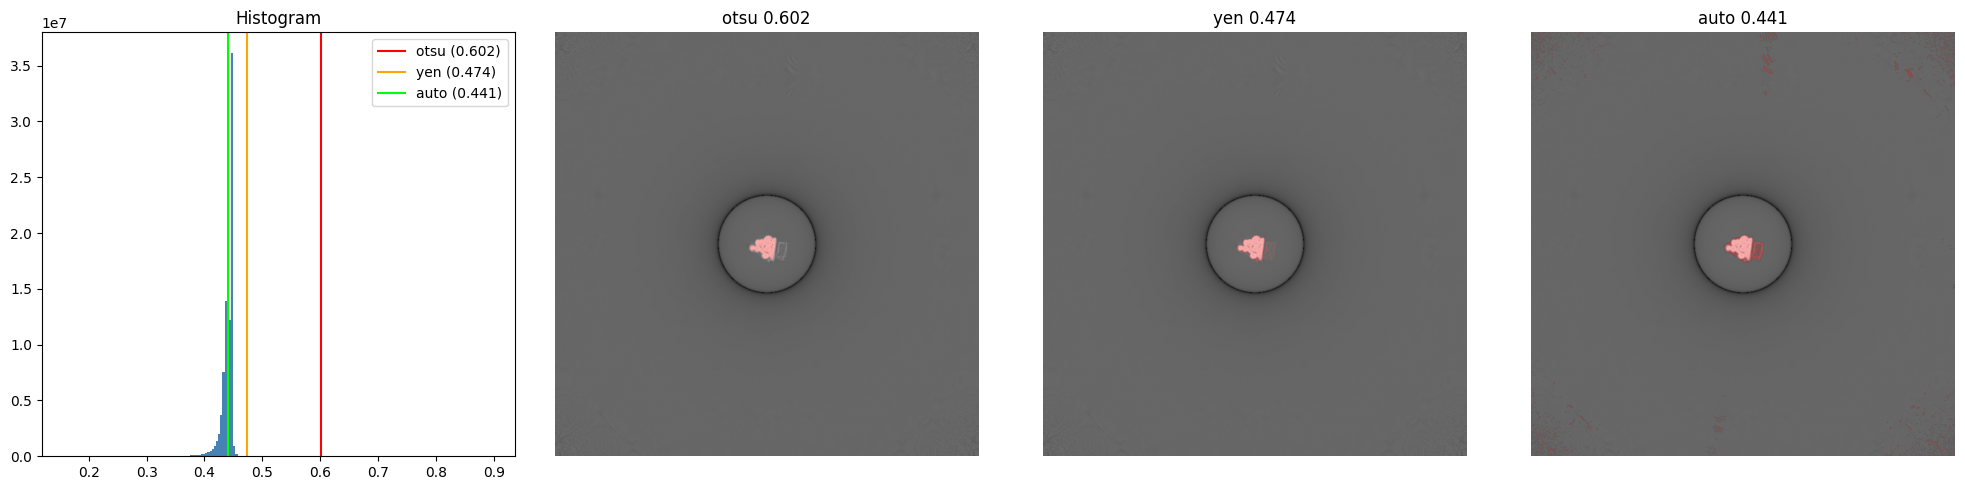

In [19]:
# compare the global thresholds on the middle slice
mid_z = vol.shape[0] // 2
slice_mid = vol_s[mid_z]

fig, axes = plt.subplots(1, len(thresholds) + 1, figsize=(20, 5))

axes[0].hist(sample, bins=200, color='steelblue')
for (name, val), c in zip(thresholds.items(), ['red', 'orange', 'lime']):
    axes[0].axvline(val, color=c, label=f"{name} ({val:.3f})")
axes[0].legend()
axes[0].set_title("Histogram")

for ax, (name, val) in zip(axes[1:], thresholds.items()):
    overlay = np.zeros((*slice_mid.shape, 4))
    overlay[slice_mid > val] = [1, 0, 0, 0.3]
    ax.imshow(slice_mid, cmap='gray')
    ax.imshow(overlay)
    ax.set_title(f"{name} {val:.3f}")
    ax.axis('off')

plt.tight_layout()
plt.savefig("/content/comparison_thresholds.png", dpi=150)
plt.show()

In [20]:
# step 2: material and air
material = (vol_s > chosen_threshold) & valid_mask
air = ~material & valid_mask

print("Material voxels:", f"{material.sum():,}")
print("Air voxels:", f"{air.sum():,}")

Material voxels: 227,215
Air voxels: 170,996,428


### Sphere pack

In [21]:
# step 3: find the sphere pack among the bright objects
material_clean = material
if use_cleanup:
    material_clean = binary_opening(material_clean, ball(1))
    material_clean = remove_small_objects(material_clean, min_size=noise_cleanup_voxels)

labeled, n_objects = scipy_label(material_clean)
sizes = np.bincount(labeled.ravel())
sizes[0] = 0

max_extent_fraction = 0.6
pack_label = None

for cand in np.argsort(sizes)[::-1][:20]:
    if sizes[cand] == 0:
        break

    coords = np.argwhere(labeled == cand)
    extent = coords.max(axis=0) - coords.min(axis=0) + 1
    extent_fraction = extent / np.array(vol.shape)
    solidity = sizes[cand] / extent.prod()

    if np.all(extent_fraction < max_extent_fraction) and solidity >= min_solidity:
        pack_label = cand
        print(f"Accepted object with {sizes[cand]:,} voxels, solidity {solidity:.2f}")
        break
    print(f"Rejected object with {sizes[cand]:,} voxels, solidity {solidity:.2f}, extent {extent_fraction.round(2)}")

if pack_label is None:
    print("No compact object found, using the largest one")
    pack_label = sizes.argmax()

sphere_pack = labeled == pack_label
other_objects = remove_small_objects(material_clean & ~sphere_pack, min_size=500)
print("Sphere pack voxels:", f"{sphere_pack.sum():,}")

Accepted object with 227,173 voxels, solidity 0.34
Sphere pack voxels: 227,173


### Local threshold and air pockets

In [22]:
# step 4a: envelope around the sphere pack
envelope = np.zeros_like(sphere_pack)
for z in range(vol.shape[0]):
    if sphere_pack[z].any():
        envelope[z] = binary_fill_holes(sphere_pack[z])

envelope = binary_closing(envelope, ball(2))
envelope = binary_fill_holes(envelope)

inside = vol_s[envelope]
local_sample = inside[::4]
print("Voxels inside the envelope:", f"{inside.size:,}")

Voxels inside the envelope: 230,641


In [23]:
# step 4b: local threshold, only from voxels inside the sphere pack
local_thresholds = {}
local_thresholds['otsu'] = threshold_otsu(local_sample)
local_thresholds['yen'] = threshold_yen(local_sample)
local_thresholds['auto'], found_valley = auto_valley_threshold(local_sample)

for name, val in local_thresholds.items():
    print(f"local {name:6s}: {val:.4f}")

local_chosen = local_thresholds[local_threshold_method] + local_threshold_offset
print(f"Using local {local_threshold_method}: {local_chosen:.4f}")

air = (vol_s < local_chosen) & valid_mask
print("Air voxels inside the pack:", f"{(air & envelope).sum():,}")

local otsu  : 0.7233
local yen   : 0.7402
local auto  : 0.7233
Using local yen: 0.7552
Air voxels inside the pack: 60,853


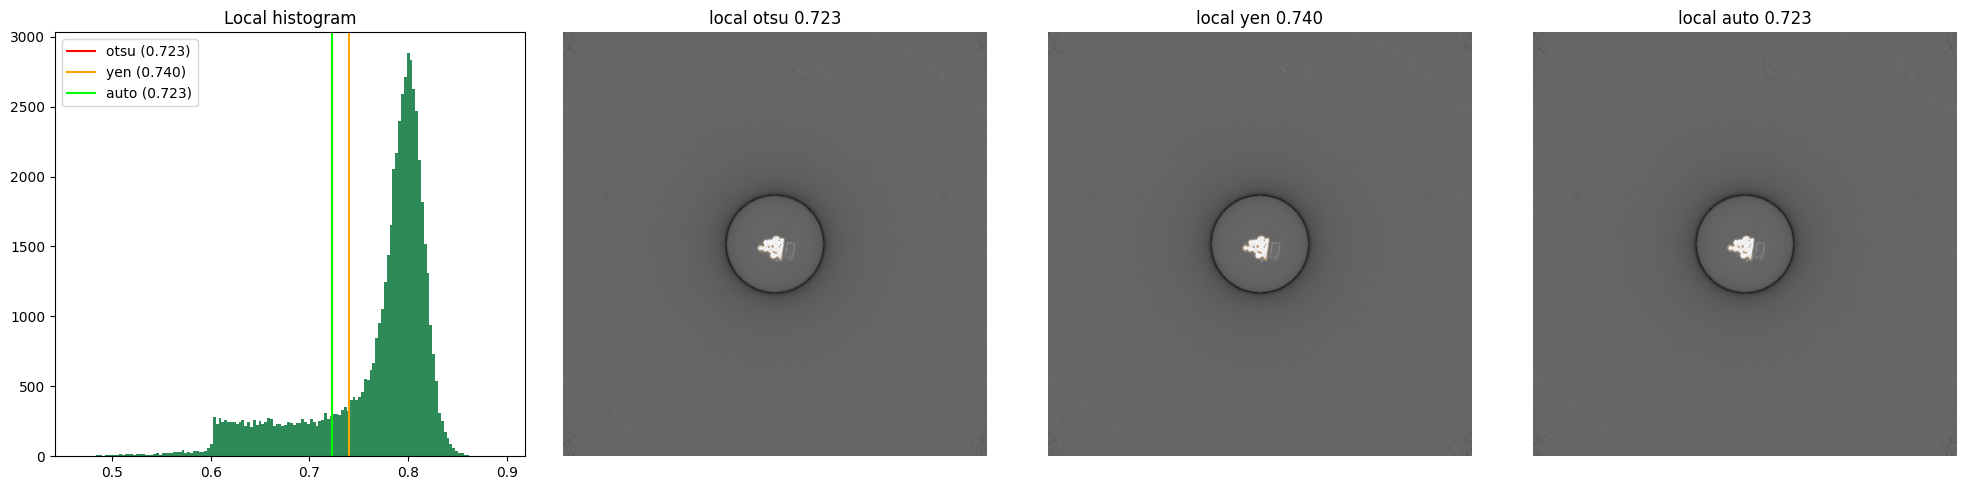

In [24]:
# compare the local thresholds on the middle slice
fig, axes = plt.subplots(1, len(local_thresholds) + 1, figsize=(20, 5))

axes[0].hist(local_sample, bins=150, color='seagreen')
for (name, val), c in zip(local_thresholds.items(), ['red', 'orange', 'lime']):
    axes[0].axvline(val, color=c, label=f"{name} ({val:.3f})")
axes[0].legend()
axes[0].set_title("Local histogram")

for ax, (name, val) in zip(axes[1:], local_thresholds.items()):
    overlay = np.zeros((*slice_mid.shape, 4))
    overlay[(slice_mid < val) & envelope[mid_z]] = [1, 0.5, 0, 0.6]
    ax.imshow(slice_mid, cmap='gray')
    ax.imshow(overlay)
    ax.set_title(f"local {name} {val:.3f}")
    ax.axis('off')

plt.tight_layout()
plt.savefig("/content/comparison_local_thresholds.png", dpi=150)
plt.show()

In [25]:
# step 5: air pockets inside the pack, away from the surface
envelope_inner = binary_erosion(envelope, ball(interior_margin))

air_pockets = air & envelope_inner
air_pockets = remove_small_objects(air_pockets, min_size=min_bubble_voxels)

# fill rings
for z in range(air_pockets.shape[0]):
    if air_pockets[z].any():
        air_pockets[z] = binary_fill_holes(air_pockets[z])
air_pockets = binary_fill_holes(air_pockets)

print("Air pocket voxels:", f"{air_pockets.sum():,}")

Air pocket voxels: 15,769


### Bubbles with DBSCAN

In [26]:
# step 6: DBSCAN groups the air voxels into bubbles
coords = np.argwhere(air_pockets).astype(np.float32)
print("Air voxels:", f"{len(coords):,}")

bubbles = []
network_clusters = []
coords_fit = coords
cluster_labels = np.array([])

if len(coords) > 0:
    if len(coords) > 600_000:
        coords_fit = coords[np.random.choice(len(coords), 600_000, replace=False)]

    min_samples = 4

    cluster_labels = DBSCAN(eps=eps, min_samples=min_samples,
                            algorithm='ball_tree', n_jobs=-1).fit_predict(coords_fit)
    print(f"Clusters found: {len(set(cluster_labels) - {-1})} (eps = {eps:.2f} voxels)")

Air voxels: 15,769
Clusters found: 52 (eps = 2.50 voxels)


In [27]:
# split real bubbles from the connected pore network and from rim artefacts at the surface
def shape_ratio(pts):
    var = np.linalg.eigvalsh(np.cov(pts.T)) + 1 / 12
    return float(np.sqrt(var[0] / var[-1]))


def measure_rim(vs_box, env_box, depth_box, margin):
    max_d = int(min(depth_box[env_box].max(), 20))
    med = np.full(max_d, np.nan)
    for d in range(1, max_d + 1):
        shell = env_box & (depth_box > d - 1) & (depth_box <= d)
        if shell.sum() >= 100:
            med[d - 1] = np.median(vs_box[shell])
    ok = np.isfinite(med)
    if ok.sum() < 4:
        return margin + 5
    start, plateau = med[ok][0], np.nanmax(med)
    reach = int(np.argmax(med >= start + 0.9 * (plateau - start))) + 1
    return int(np.clip(reach + 2, margin + 2, 15))

pack_coords = np.argwhere(sphere_pack)
pack_extent = pack_coords.max(axis=0) - pack_coords.min(axis=0) + 1


if edge_filter:
    zs, ys, xs = (np.nonzero(envelope.any(axis=a))[0] for a in [(1, 2), (0, 2), (0, 1)])
    box = (slice(zs.min(), zs.max() + 1), slice(ys.min(), ys.max() + 1), slice(xs.min(), xs.max() + 1))
    depth_box = distance_transform_edt(np.pad(envelope[box], 1)).astype(np.float32)[1:-1, 1:-1, 1:-1]
    box_start = np.array([box[0].start, box[1].start, box[2].start])


    edge_depth_used = edge_depth_manual or measure_rim(vol_s[box], envelope[box], depth_box, interior_margin)
    print(f"Edge filter: surface layer = {edge_depth_used} voxels ({edge_depth_used * voxel_edge_mm:.1f} mm), "
          f"small < {edge_small_voxels} voxels, thin <= {edge_thin} voxels, large > {edge_max_voxels} voxels")

edge_clusters = []

for cid in sorted(set(cluster_labels) - {-1}):
    pts = coords_fit[cluster_labels == cid]
    if len(pts) < min_bubble_voxels:
        continue

    extent = pts.max(axis=0) - pts.min(axis=0) + 1
    entry = {"raw_cid": int(cid), "size": len(pts),
             "centroid": pts.mean(axis=0).tolist(), "mm3": len(pts) * voxel_mm3}
    entry["shape"] = shape_ratio(pts)

    is_edge = False
    if edge_filter:
        idx = (pts - box_start).astype(int)
        near_surface = np.mean(depth_box[idx[:, 0], idx[:, 1], idx[:, 2]] <= edge_depth_used) >= edge_fraction
        is_edge = near_surface and (len(pts) < edge_small_voxels or extent.min() <= edge_thin
                                    or len(pts) > edge_max_voxels or entry["shape"] < edge_elongation)

    if np.any(extent / pack_extent > network_extent_fraction):
        network_clusters.append(entry)
    elif is_edge:
        edge_clusters.append(entry)
    else:
        bubbles.append(entry)

bubbles.sort(key=lambda b: b["size"], reverse=True)
for i, b in enumerate(bubbles):
    b["id"] = i + 1

print("Bubbles:", len(bubbles))
print("Pore network clusters (not counted):", len(network_clusters))
print("Edge artefacts removed:", len(edge_clusters))
for e in edge_clusters[:15]:
    z, y, x = e["centroid"]
    print(f"  removed: {e['size']} voxels, shape {e['shape']:.2f}, at z {z:.0f}, y {y:.0f}, x {x:.0f}")


Bubbles: 52
Pore network clusters (not counted): 0
Edge artefacts removed: 0


In [28]:
# masks for plotting and the bubble report
bubble_mask = np.zeros_like(air_pockets, dtype=bool)
network_mask = np.zeros_like(air_pockets, dtype=bool)

for b in bubbles:
    idx = coords_fit[cluster_labels == b["raw_cid"]].astype(int)
    bubble_mask[idx[:, 0], idx[:, 1], idx[:, 2]] = True
for n in network_clusters:
    idx = coords_fit[cluster_labels == n["raw_cid"]].astype(int)
    network_mask[idx[:, 0], idx[:, 1], idx[:, 2]] = True

if bubbles:
    sizes_b = [b["size"] for b in bubbles]
    print("===== AIR BUBBLE REPORT =====")
    print(f"Threshold ({threshold_method}): {chosen_threshold:.4f}")
    print(f"Bubbles          : {len(bubbles)}")
    print(f"Largest          : {max(sizes_b)} voxels ({max(sizes_b) * voxel_mm3:.3f} mm3)")
    print(f"Smallest         : {min(sizes_b)} voxels ({min(sizes_b) * voxel_mm3:.3f} mm3)")
    print(f"Average          : {np.mean(sizes_b):.1f} voxels")
    print(f"Total void volume: {sum(sizes_b) * voxel_mm3:.3f} mm3")

    with open("/content/bubble_report.txt", "w") as f:
        f.write(f"Threshold method: {threshold_method} ({chosen_threshold:.4f})\n")
        f.write(f"DBSCAN eps={eps:.2f} voxels, min_samples={min_samples}\n")
        f.write("ID, Size(voxels), Size(mm3), Z, Y, X\n")
        for b in bubbles:
            z, y, x = b["centroid"]
            f.write(f"{b['id']}, {b['size']}, {b['mm3']:.4f}, {z:.1f}, {y:.1f}, {x:.1f}\n")
    print("Saved bubble_report.txt")
else:
    print("No bubbles found")

===== AIR BUBBLE REPORT =====
Threshold (otsu): 0.6019
Bubbles          : 52
Largest          : 14318 voxels (916.352 mm3)
Smallest         : 4 voxels (0.256 mm3)
Average          : 301.1 voxels
Total void volume: 1001.984 mm3
Saved bubble_report.txt


## 6. Plots

In [29]:
# crop box around the sphere pack and the z range to show
colors = ['#0a0a1a', '#0d2137', '#1a4a6b', '#2e7fb8', '#6db8d4', '#b8dce8', '#e8f4f8', '#ffffff']
ct_cmap = LinearSegmentedColormap.from_list('ct_navy', colors, N=256)

margin = 30
pack_coords = np.argwhere(sphere_pack)

if len(pack_coords) > 0:
    ymin, xmin = pack_coords.min(axis=0)[1:]
    ymax, xmax = pack_coords.max(axis=0)[1:]
    ymin, xmin = max(0, ymin - margin), max(0, xmin - margin)
    ymax, xmax = min(vol.shape[1] - 1, ymax + margin), min(vol.shape[2] - 1, xmax + margin)

    # only slices where the pack is at least 40 percent of its biggest area
    area_per_z = sphere_pack.sum(axis=(1, 2))
    good_z = np.where(area_per_z > 0.40 * area_per_z.max())[0]
    zmin_substantial, zmax_substantial = good_z.min(), good_z.max()
else:
    ymin, ymax, xmin, xmax = 0, vol.shape[1] - 1, 0, vol.shape[2] - 1
    zmin_substantial, zmax_substantial = 0, vol.shape[0] - 1

print(f"Crop: y {ymin}-{ymax}, x {xmin}-{xmax}, z {zmin_substantial}-{zmax_substantial}")

Crop: y 353-464, x 328-457, z 319-480


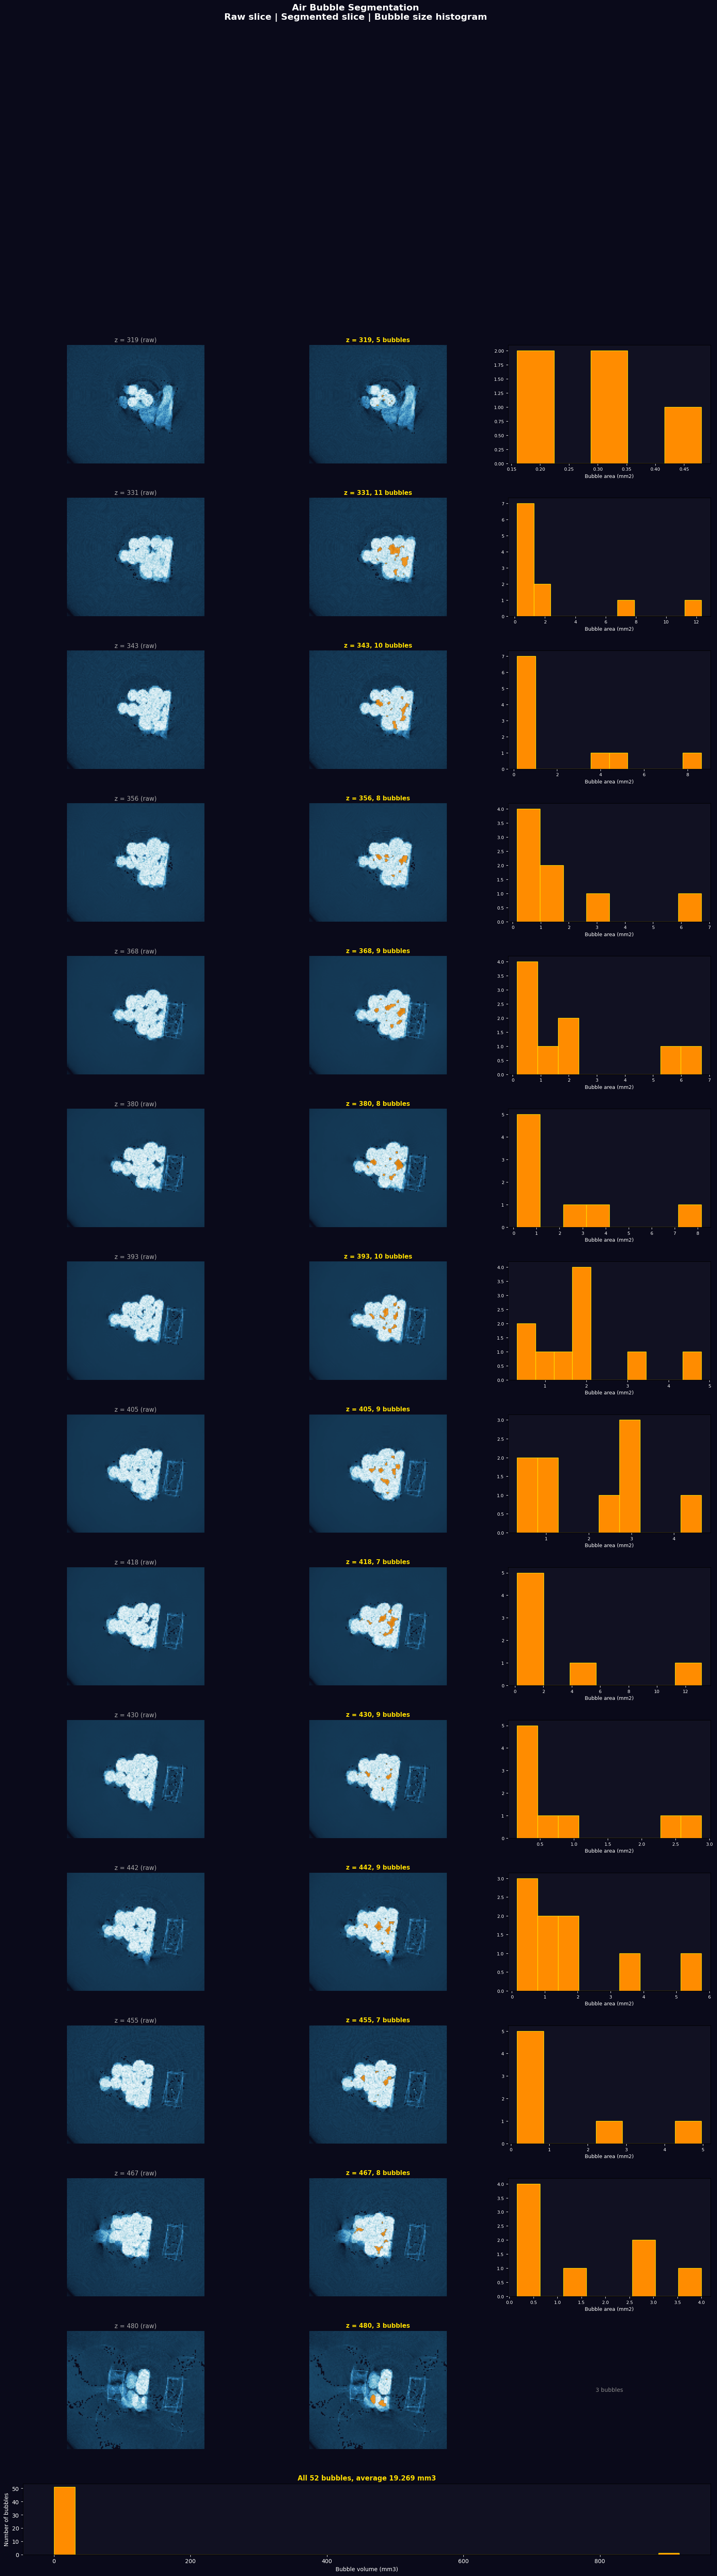

In [30]:
# 2D preview: raw slice, segmented slice and size histogram for each slice
n_slices_shown = 14
slice_z = np.linspace(zmin_substantial, zmax_substantial, n_slices_shown, dtype=int)
pixel_area_mm2 = voxel_edge_mm ** 2

fig = plt.figure(figsize=(22, 4.8 * n_slices_shown + 4), facecolor='#0a0a1a')
gs = fig.add_gridspec(n_slices_shown + 1, 3, width_ratios=[1, 1, 0.9],
                      height_ratios=[1] * n_slices_shown + [0.6])
fig.suptitle("Air Bubble Segmentation\nRaw slice | Segmented slice | Bubble size histogram",
             fontsize=16, color='white', y=0.999, fontweight='bold')

for row, z in enumerate(slice_z):
    ax_raw = fig.add_subplot(gs[row, 0])
    ax_seg = fig.add_subplot(gs[row, 1])
    ax_hist = fig.add_subplot(gs[row, 2])

    show = vol[z, ymin:ymax, xmin:xmax].copy()
    show[other_objects[z, ymin:ymax, xmin:xmax]] = 0
    show[~valid_mask[z, ymin:ymax, xmin:xmax]] = 0

    ax_raw.imshow(show, cmap=ct_cmap, vmin=0.28, vmax=0.95)
    ax_raw.set_title(f"z = {z} (raw)", color='#aaaaaa', fontsize=11)

    slice_air = air_pockets[z, ymin:ymax, xmin:xmax]
    overlay = np.zeros((*slice_air.shape, 4))
    overlay[slice_air] = [1, 0.55, 0, 0.85]
    ax_seg.imshow(show, cmap=ct_cmap, vmin=0.28, vmax=0.95)
    ax_seg.imshow(overlay)

    labeled2d, n_reg = scipy_label(slice_air)
    ax_seg.set_title(f"z = {z}, {n_reg} bubbles", color='#ffdd00', fontsize=11, fontweight='bold')
    ax_raw.axis('off')
    ax_seg.axis('off')

    ax_hist.set_facecolor('#111122')
    if n_reg >= 5:
        areas = np.bincount(labeled2d.ravel())[1:] * pixel_area_mm2
        ax_hist.hist(areas, bins=min(15, n_reg), color='#ff8c00', edgecolor='#ffdd00')
        ax_hist.set_xlabel("Bubble area (mm2)", color='white', fontsize=9)
        ax_hist.tick_params(colors='white', labelsize=8)
    else:
        ax_hist.text(0.5, 0.5, f"{n_reg} bubbles", ha='center', va='center', color='#888888')
        ax_hist.axis('off')

# overall histogram at the bottom, then save the figure
ax_all = fig.add_subplot(gs[n_slices_shown, :])
ax_all.set_facecolor('#111122')

if bubbles:
    sizes_mm3 = [b["mm3"] for b in bubbles]
    ax_all.hist(sizes_mm3, bins=30, color='#ff8c00', edgecolor='#ffdd00')
    ax_all.set_xlabel("Bubble volume (mm3)", color='white')
    ax_all.set_ylabel("Number of bubbles", color='white')
    ax_all.set_title(f"All {len(bubbles)} bubbles, average {np.mean(sizes_mm3):.3f} mm3",
                     color='#ffdd00', fontweight='bold')
    ax_all.tick_params(colors='white')
else:
    ax_all.text(0.5, 0.5, "No bubbles detected", ha='center', color='white')
    ax_all.axis('off')

plt.subplots_adjust(wspace=0.08, hspace=0.3)
plt.savefig("/content/slices_preview.png", dpi=400, facecolor='#0a0a1a', bbox_inches='tight')
plt.show()
plt.close()

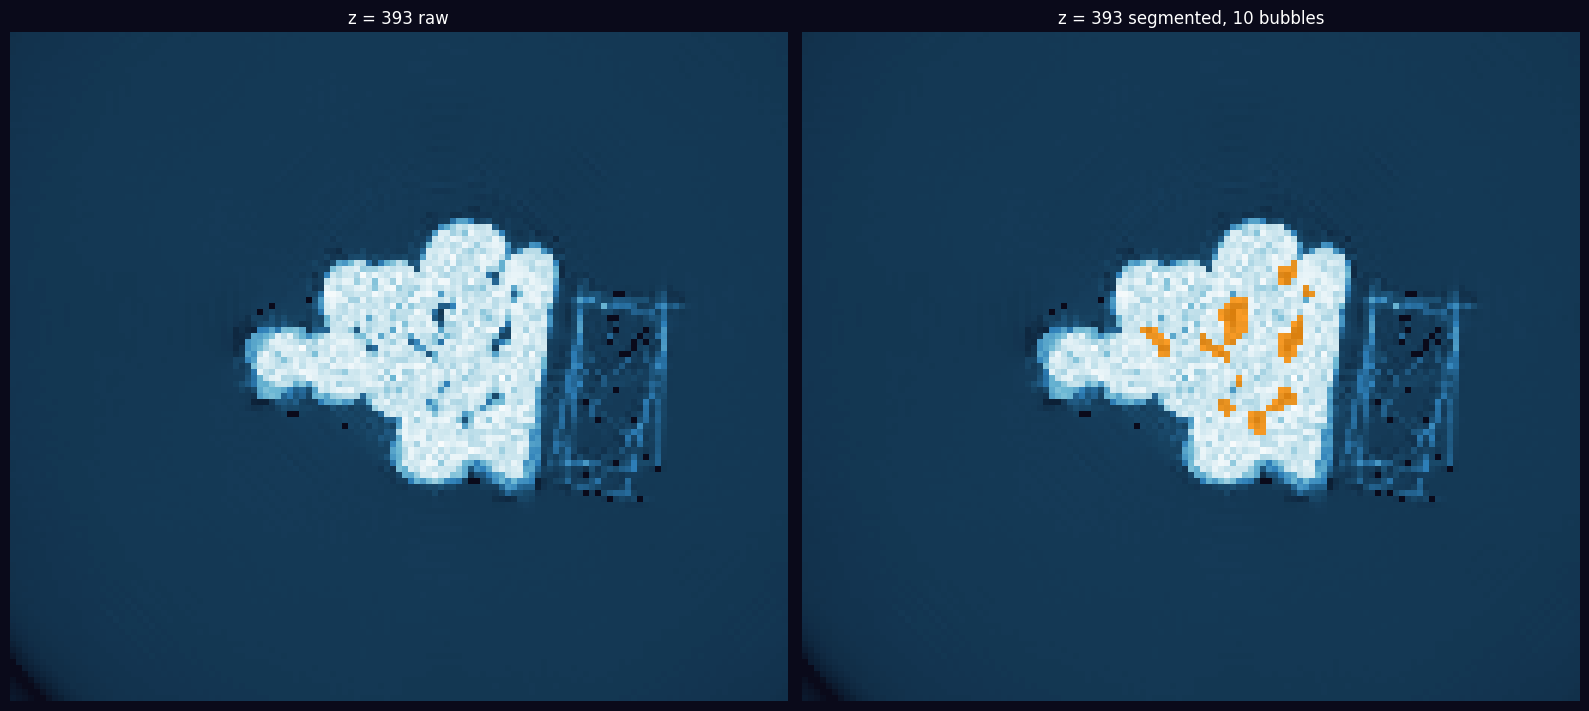

In [31]:
# one slice in high resolution
z_to_view = 393   # change

show = vol[z_to_view, ymin:ymax, xmin:xmax].copy()
show[other_objects[z_to_view, ymin:ymax, xmin:xmax]] = 0
show[~valid_mask[z_to_view, ymin:ymax, xmin:xmax]] = 0

slice_air = air_pockets[z_to_view, ymin:ymax, xmin:xmax]
overlay = np.zeros((*slice_air.shape, 4))
overlay[slice_air] = [1, 0.55, 0, 0.85]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8), facecolor='#0a0a1a')
ax1.imshow(show, cmap=ct_cmap, vmin=0.28, vmax=0.95)
ax1.set_title(f"z = {z_to_view} raw", color='white')
ax2.imshow(show, cmap=ct_cmap, vmin=0.28, vmax=0.95)
ax2.imshow(overlay)
ax2.set_title(f"z = {z_to_view} segmented, {scipy_label(slice_air)[1]} bubbles", color='white')
ax1.axis('off')
ax2.axis('off')

plt.tight_layout()
plt.savefig(f"/content/slice_{z_to_view}_full_res.png", dpi=600, facecolor='#0a0a1a', bbox_inches='tight')
plt.show()

In [32]:
# 3D viewer: sphere pack and air bubbles
def make_mesh(mask, step, color, opacity, name):
    verts, faces, _, _ = marching_cubes(mask.astype(np.float32), level=0.5, step_size=step)
    return go.Mesh3d(x=verts[:, 2], y=verts[:, 1], z=verts[:, 0],
                     i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
                     opacity=opacity, color=color, name=name, showscale=False)

if bubbles:
    meshes = [make_mesh(sphere_pack, 4, '#4488cc', 0.15, "Spheres")]
    if bubble_mask.any():
        meshes.append(make_mesh(bubble_mask, 2, '#33ff66', 0.85, "Air bubbles"))

    axis = dict(backgroundcolor='#0d0d1a', gridcolor='#2a2a4a', showbackground=True,
                tickfont=dict(color='white'))
    fig3d = go.Figure(data=meshes)
    fig3d.update_layout(
        title=dict(text=f"Air bubbles: {len(bubbles)}", font=dict(color='white', size=14)),
        paper_bgcolor='#06060f', font=dict(color='white'),
        scene=dict(xaxis=dict(title="X", **axis), yaxis=dict(title="Y", **axis),
                   zaxis=dict(title="Z", **axis), bgcolor='#06060f', aspectmode='data'),
        legend=dict(bgcolor='#111122', font=dict(color='white')),
        margin=dict(l=0, r=0, b=0, t=50))
    fig3d.show()
else:
    print("No bubbles, 3D viewer skipped")

In [33]:
# copy the results to Drive
for fname in ["comparison_thresholds.png", "comparison_local_thresholds.png",
              "slices_preview.png", "bubble_report.txt"]:
    if os.path.exists(f"/content/{fname}"):
        shutil.copy2(f"/content/{fname}", f"{PROJECT_DIR}/{fname}")
        print("Copied", fname)
    else:
        print("Missing", fname)

Copied comparison_thresholds.png
Copied comparison_local_thresholds.png
Copied slices_preview.png
Copied bubble_report.txt


## 7. Save the 2D output of the normal data


In [34]:
# validation export: slices to mark by hand, plus prediction for the same slices
from PIL import Image
import json

PRED_SOURCE = "bubbles"   # "bubbles" = discrete bubbles only, "air_pockets" = also the pore network
N_SLICES = 12
UPSCALE = 6
DATASET = os.path.splitext(zip_name)[0] if 'zip_name' in globals() else "dataset"

folder = f"{PROJECT_DIR}/validation/{DATASET}"
for sub in ["raw", "pred", "marked"]:
    os.makedirs(f"{folder}/{sub}", exist_ok=True)

pred_volume = bubble_mask if PRED_SOURCE == "bubbles" else air_pockets
z_list = np.linspace(zmin_substantial, zmax_substantial, N_SLICES, dtype=int)

# same colours as the 2D preview, lower window so dark bubbles stand out
low = np.percentile(vol_s[envelope], 1)
high = 0.95

for z in z_list:
    scaled = np.clip((vol_s[z, ymin:ymax, xmin:xmax] - low) / (high - low), 0, 1)
    rgb = (ct_cmap(scaled)[:, :, :3] * 255).astype(np.uint8)
    img = Image.fromarray(rgb)
    img = img.resize((img.width * UPSCALE, img.height * UPSCALE), Image.NEAREST)
    img.save(f"{folder}/raw/slice_{z}_raw.png")

    pred = pred_volume[z, ymin:ymax, xmin:xmax]
    Image.fromarray(pred.astype(np.uint8) * 255).save(f"{folder}/pred/slice_{z}_pred.png")

info = {"dataset": DATASET, "z_list": [int(z) for z in z_list], "upscale": UPSCALE,
        "pred_source": PRED_SOURCE, "crop_y": [int(ymin), int(ymax)], "crop_x": [int(xmin), int(xmax)],
        "voxel_edge_mm": float(voxel_edge_mm)}
with open(f"{folder}/info.json", "w") as f:
    json.dump(info, f, indent=2)

print("Saved to:", folder)
print("Slices:", info["z_list"])
print("Next: mark the bubbles in the raw images in pure red (255, 0, 0),")
print("save them as slice_<z>_marked.png into the marked folder")

Saved to: /content/drive/MyDrive/CT_Bubble_Project/validation/Projections
Slices: [319, 333, 348, 362, 377, 392, 406, 421, 436, 450, 465, 480]
Next: mark the bubbles in the raw images in pure red (255, 0, 0),
save them as slice_<z>_marked.png into the marked folder


## 8. Validation with test data


### 8a. Choose the test zip

In [35]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, shutil, zipfile

VAL_ZIP_NAME = "Projections (2).zip"      # exact name of the TEST zip in the project folder
NORMAL_DATASET = ""    # validation folder of the normal data, empty = the dataset of the algorithm ran before

PROJECT_DIR = "/content/drive/MyDrive/CT_Bubble_Project"
VAL_PROJ_DIR = "/content/ValProjections"

zips = [f for f in os.listdir(PROJECT_DIR) if f.lower().endswith(".zip")]
print("Zip files in the project folder:", zips)

if not VAL_ZIP_NAME:
    raise ValueError("Type the name of the test zip in VAL_ZIP_NAME")
if VAL_ZIP_NAME not in zips:
    raise FileNotFoundError(f"{VAL_ZIP_NAME} is not in the project folder, check the spelling")

TEST_NAME = os.path.splitext(VAL_ZIP_NAME)[0]

# the normal data: its 2D output was saved by the export cell at the end of the algorithm part
marker = f"{PROJECT_DIR}/current_dataset.txt"
if not NORMAL_DATASET and os.path.exists(marker):
    NORMAL_DATASET = os.path.splitext(open(marker).read().strip())[0]

normal_folder = f"{PROJECT_DIR}/validation/{NORMAL_DATASET}"
if not os.path.exists(f"{normal_folder}/info.json"):
    found = os.listdir(f"{PROJECT_DIR}/validation") if os.path.exists(f"{PROJECT_DIR}/validation") else []
    print("Folders in validation:", found)
    raise FileNotFoundError("No saved 2D output for the normal data, run the export cell of the algorithm part "
                            "or set NORMAL_DATASET to one of the folders above")
if TEST_NAME == NORMAL_DATASET:
    raise ValueError("The test zip must be a different dataset than the normal data")

normal_info = json.load(open(f"{normal_folder}/info.json"))
test_folder = f"{PROJECT_DIR}/validation/TEST_{TEST_NAME}"
for sub in ["raw", "marked"]:
    os.makedirs(f"{test_folder}/{sub}", exist_ok=True)

print("Test data   :", VAL_ZIP_NAME)
print("Normal data :", NORMAL_DATASET, "| slices saved:", normal_info["z_list"])
print("Test folder :", test_folder)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Zip files in the project folder: ['Projections.zip', 'Projections(1).zip', 'Projections (2).zip']
Test data   : Projections (2).zip
Normal data : Projections | slices saved: [319, 333, 348, 362, 377, 392, 406, 421, 436, 450, 465, 480]
Test folder : /content/drive/MyDrive/CT_Bubble_Project/validation/TEST_Projections (2)


In [36]:
# unzip the test projections
local_marker = f"{VAL_PROJ_DIR}/.extracted_from.txt"
done_name = open(local_marker).read().strip() if os.path.exists(local_marker) else None

if done_name == VAL_ZIP_NAME:
    print("Already unzipped, skipping")
else:
    shutil.rmtree(VAL_PROJ_DIR, ignore_errors=True)
    os.makedirs(VAL_PROJ_DIR)

    print("Copying the zip from Drive, this can take a few minutes...")
    shutil.copy2(f"{PROJECT_DIR}/{VAL_ZIP_NAME}", "/content/test_upload.zip")

    print("Unzipping...")
    with zipfile.ZipFile("/content/test_upload.zip") as zf:
        zf.extractall(VAL_PROJ_DIR)

    os.remove("/content/test_upload.zip")
    open(local_marker, "w").write(VAL_ZIP_NAME)

n_raw = sum(f.endswith(".raw") for _, _, fs in os.walk(VAL_PROJ_DIR) for f in fs)
n_tiff = sum(f.lower().endswith((".tif", ".tiff")) for _, _, fs in os.walk(VAL_PROJ_DIR) for f in fs)
print(f"Found {n_raw} .raw files and {n_tiff} .tiff files")

Copying the zip from Drive, this can take a few minutes...
Unzipping...
Found 2001 .raw files and 1 .tiff files


### 8b. Reconstruct the test data

In [37]:
# install ASTRA (needs the GPU runtime)
!pip install -q astra-toolbox

import astra
print("ASTRA version:", astra.__version__)


ASTRA version: 2.5.0


In [38]:
# find the test projection files and set the scan settings
import gc, time
import numpy as np
from PIL import Image
from collections import Counter

raw_files, tiff_files = [], []
for root, dirs, fs in os.walk(VAL_PROJ_DIR):
    for f in fs:
        if f.endswith(".raw") and "reco" not in f.lower():
            raw_files.append(os.path.join(root, f))
        elif f.lower().endswith((".tif", ".tiff")):
            tiff_files.append(os.path.join(root, f))

if not raw_files or not tiff_files:
    raise FileNotFoundError("No .raw or .tiff files found, run the unzip cell first")

proj_folder = Counter(os.path.dirname(p) for p in raw_files).most_common(1)[0][0]
flat_file = next((t for t in tiff_files if "diff" in t.lower()), tiff_files[0])

files = sorted(f for f in os.listdir(proj_folder) if f.endswith(".raw") and "reco" not in f.lower())
print(f"{len(files)} projections in {proj_folder}")
print("Flat field file:", flat_file)

# scan settings, same as the normal data
nx, ny = 2000, 2016
header_bytes = 2048
FDD = 1450.731801543734
FOD = 672.9998794381496
pixel_size = 0.2
detector_bin = 2
vol_size = 800
angle_step = 1
files = files[::angle_step]


2001 projections in /content/ValProjections/Projections
Flat field file: /content/ValProjections/Projections/HSKO_1-5_230kV_250uA_1950ms_1xSn_2xCu_1xAl_2x_Diff.tiff


In [39]:
# load the flat field and all test projections
start = time.time()
nrow, ncol = ny // detector_bin, nx // detector_bin

def bin_image(img):
    return img.reshape(nrow, detector_bin, ncol, detector_bin).mean(axis=(1, 3))

flat = bin_image(np.array(Image.open(flat_file)).astype(np.float32))
flat = np.clip(flat, 1e-6, None)

projections = np.empty((len(files), nrow, ncol), dtype=np.float32)
for i, f in enumerate(files):
    with open(os.path.join(proj_folder, f), "rb") as fp:
        fp.seek(header_bytes)
        img = np.fromfile(fp, dtype=np.uint16, count=nx * ny)
    projections[i] = bin_image(img.reshape(ny, nx).astype(np.float32))

    if (i + 1) % 200 == 0:
        print(f"Loaded {i + 1} of {len(files)} projections ({time.time() - start:.0f}s)")

Loaded 200 of 2001 projections (14s)
Loaded 400 of 2001 projections (28s)
Loaded 600 of 2001 projections (42s)
Loaded 800 of 2001 projections (56s)
Loaded 1000 of 2001 projections (70s)
Loaded 1200 of 2001 projections (85s)
Loaded 1400 of 2001 projections (99s)
Loaded 1600 of 2001 projections (113s)
Loaded 1800 of 2001 projections (127s)
Loaded 2000 of 2001 projections (142s)


In [40]:
# flat field correction and centre of rotation
projections /= flat[np.newaxis]
np.clip(projections, 1e-6, None, out=projections)
np.log(projections, out=projections)
projections *= -1

mid = projections.shape[1] // 2
first_row = projections[0, mid]
last_row = projections[-1, mid]

scores = [np.sum((first_row - np.roll(last_row, s)) ** 2) for s in range(-20, 21)]
best_shift = int(np.argmin(scores)) - 20
print("Best centre of rotation shift:", best_shift, "pixels")

for i in range(projections.shape[0]):
    projections[i] = np.roll(projections[i], best_shift, axis=1)

Best centre of rotation shift: 0 pixels


In [41]:
# FDK reconstruction of the test data
proj_astra = np.transpose(projections, (1, 0, 2))
angles = np.linspace(0, 2 * np.pi, proj_astra.shape[1], endpoint=False)
pixel_size_eff = pixel_size * detector_bin

proj_geom = astra.create_proj_geom('cone', pixel_size_eff, pixel_size_eff,
                                   proj_astra.shape[0], proj_astra.shape[2],
                                   angles, FOD, FDD - FOD)
vol_geom = astra.create_vol_geom(vol_size, vol_size, vol_size)

del projections
gc.collect()

proj_id = astra.data3d.create('-sino', proj_geom, proj_astra)
vol_id = astra.data3d.create('-vol', vol_geom)

cfg = astra.astra_dict('FDK_CUDA')
cfg['ProjectionDataId'] = proj_id
cfg['ReconstructionDataId'] = vol_id
cfg['option'] = {'GPUindex': 0}
alg_id = astra.algorithm.create(cfg)

t = time.time()
astra.algorithm.run(alg_id)
recon = astra.data3d.get(vol_id)
print(f"Reconstruction done in {time.time() - t:.0f} seconds")

astra.algorithm.delete(alg_id)
astra.data3d.delete(proj_id)
astra.data3d.delete(vol_id)
del proj_astra
gc.collect()

test_vol = recon.astype(np.float32)
test_vol = (test_vol - test_vol.min()) / (test_vol.max() - test_vol.min() + 1e-8)
del recon
gc.collect()
print("Test volume:", test_vol.shape)

Reconstruction done in 19 seconds
Test volume: (800, 800, 800)


# 8c. denoise the test volume

In [42]:
# denoise the test volume slice by slice
from skimage.restoration import denoise_nl_means, estimate_sigma

dn_path = f"{test_folder}/test_reconstruction_denoised.npy"
checkpoint_path = f"{test_folder}/test_denoised_checkpoint.npy"

if os.path.exists(dn_path):
    test_vol_dn = np.load(dn_path)
    print("Loaded the denoised test volume from Drive:", test_vol_dn.shape)
else:
    start_z = 0
    test_vol_dn = np.zeros_like(test_vol)

    if os.path.exists(checkpoint_path):
        test_vol_dn = np.load(checkpoint_path)
        empty = [z for z in range(test_vol.shape[0]) if not test_vol_dn[z].any()]
        start_z = empty[0] if empty else test_vol.shape[0]
        print("Resuming from slice", start_z)

    start = time.time()
    for z in range(start_z, test_vol.shape[0]):
        s = test_vol[z].astype(np.float64)
        sigma = np.mean(estimate_sigma(s))
        test_vol_dn[z] = denoise_nl_means(s, h=1.15 * sigma, fast_mode=True,
                                          patch_size=5, patch_distance=6)

        if (z + 1) % 20 == 0:
            left = (test_vol.shape[0] - z - 1) * (time.time() - start) / (z + 1 - start_z)
            print(f"Slice {z + 1} of {test_vol.shape[0]}, about {left / 60:.1f} min left")
        if (z + 1) % 50 == 0:
            np.save(checkpoint_path, test_vol_dn)

    test_vol_dn -= test_vol_dn.min()
    test_vol_dn /= (test_vol_dn.max() + 1e-8)
    np.save(dn_path, test_vol_dn)
    if os.path.exists(checkpoint_path):
        os.remove(checkpoint_path)
    print("Saved test_reconstruction_denoised.npy")

Loaded the denoised test volume from Drive: (800, 800, 800)


### 8c-2. Find the bubbles in the test data

In [43]:
# test data: settings (the same values as of section 5)
import gc
from scipy.ndimage import binary_fill_holes, distance_transform_edt, label as scipy_label
from skimage.filters import gaussian, threshold_otsu, threshold_yen
from skimage.morphology import ball, remove_small_objects, binary_closing, binary_erosion, binary_opening
from sklearn.cluster import DBSCAN

MODE = "adaptive"
voxel_edge_mm = pixel_size * detector_bin
voxel_mm3 = voxel_edge_mm ** 3

local_threshold_method = 'otsu'
local_threshold_offset = 0.0
min_bubble_voxels = max(1, round(0.5 / voxel_mm3))      # smallest bubble: 0.5 mm3
interior_margin = max(1, round(0.6 / voxel_edge_mm))    # stay 0.6 mm away from the surface
eps = 0.5 / voxel_edge_mm                               # DBSCAN distance
min_solidity = 0.15
network_extent_fraction = 0.3                           # wider than 30 percent of the pack = pore network
noise_cleanup_voxels = max(1, round(0.0003 / voxel_mm3))
use_cleanup = True

print("Smallest bubble:", min_bubble_voxels, "voxels | surface margin:", interior_margin, "voxels")

Smallest bubble: 8 voxels | surface margin: 1 voxels


In [44]:
# step 1: smooth the volume and find the padding (voxels outside the scan)
test_vol_s = gaussian(test_vol_dn, sigma=0.7)

rounded = np.round(test_vol_s[::4, ::4, ::4].ravel(), 4)
values, counts = np.unique(rounded, return_counts=True)
fill_value = values[np.argmax(counts)]
test_valid = np.abs(test_vol_s - fill_value) > 0.001

In [45]:
# step 2: global threshold, bright = material
test_threshold = threshold_otsu(test_vol_s[test_valid][::2])
test_material = (test_vol_s > test_threshold) & test_valid
print(f"Global otsu threshold: {test_threshold:.4f}")

Global otsu threshold: 0.5820


In [46]:
# step 3: the sphere pack is the biggest compact bright object
material_clean = binary_opening(test_material, ball(1))
material_clean = remove_small_objects(material_clean, min_size=noise_cleanup_voxels)
labeled, n_objects = scipy_label(material_clean)
sizes = np.bincount(labeled.ravel())
sizes[0] = 0

pack_label = None
for cand in np.argsort(sizes)[::-1][:20]:
    if sizes[cand] == 0:
        break
    coords = np.argwhere(labeled == cand)
    extent = coords.max(axis=0) - coords.min(axis=0) + 1
    solidity = sizes[cand] / extent.prod()
    if np.all(extent / np.array(test_vol_dn.shape) < 0.6) and solidity >= min_solidity:
        pack_label = cand
        break
if pack_label is None:
    pack_label = sizes.argmax()

test_pack = labeled == pack_label
print("Sphere pack voxels:", f"{test_pack.sum():,}")

Sphere pack voxels: 465,592


In [47]:
# step 4: outline of the pack (fill the gaps between the spheres) and the local threshold inside it
test_envelope = np.zeros_like(test_pack)
for z in range(test_pack.shape[0]):
    if test_pack[z].any():
        test_envelope[z] = binary_fill_holes(test_pack[z])
test_envelope = binary_closing(test_envelope, ball(2))
test_envelope = binary_fill_holes(test_envelope)

sample = test_vol_s[test_envelope][::4]
local_values = {'otsu': threshold_otsu(sample), 'yen': threshold_yen(sample)}
test_local_chosen = local_values[local_threshold_method] + local_threshold_offset

test_air = (test_vol_s < test_local_chosen) & test_valid
print(f"Local {local_threshold_method} threshold: {test_local_chosen:.4f}")

Local otsu threshold: 0.6605


In [48]:
# step 5: air pockets inside the pack, away from the surface
test_air_pockets = test_air & binary_erosion(test_envelope, ball(interior_margin))
test_air_pockets = remove_small_objects(test_air_pockets, min_size=min_bubble_voxels)

# fill rings
for z in range(test_air_pockets.shape[0]):
    if test_air_pockets[z].any():
        test_air_pockets[z] = binary_fill_holes(test_air_pockets[z])
test_air_pockets = binary_fill_holes(test_air_pockets)

print("Air pocket voxels:", f"{test_air_pockets.sum():,}")

Air pocket voxels: 71,660


In [49]:
# step 6: DBSCAN groups the air voxels into bubbles
coords = np.argwhere(test_air_pockets).astype(np.float32)
if len(coords) > 600_000:
    coords = coords[np.random.choice(len(coords), 600_000, replace=False)]

labels = np.array([])
if len(coords) > 0:
    labels = DBSCAN(eps=eps, min_samples=4, algorithm='ball_tree', n_jobs=-1).fit_predict(coords)

print("Clusters found:", len(set(labels) - {-1}))

Clusters found: 217


In [50]:
# edge filter functions
def shape_ratio(pts):
    var = np.linalg.eigvalsh(np.cov(pts.T)) + 1 / 12
    return float(np.sqrt(var[0] / var[-1]))


def measure_blur(vs_box, env_box, depth_box, margin):
    # median brightness layer by layer from the surface inwards
    max_d = int(min(depth_box[env_box].max(), 20))
    med = np.full(max_d, np.nan)
    for d in range(1, max_d + 1):
        shell = env_box & (depth_box > d - 1) & (depth_box <= d)
        if shell.sum() >= 100:
            med[d - 1] = np.median(vs_box[shell])
    ok = np.isfinite(med)
    if ok.sum() < 4:
        return margin + 5, margin + 3
    start, plateau = med[ok][0], np.nanmax(med)
    reach = int(np.argmax(med >= start + 0.9 * (plateau - start))) + 1
    return int(np.clip(reach + 2, margin + 2, 15)), int(max(reach, 2))

In [51]:
# step 7: how wide is the blurred surface layer?
pack_coords = np.argwhere(test_pack)
pack_extent = pack_coords.max(axis=0) - pack_coords.min(axis=0) + 1

# box around the pack, and the depth of every voxel below the surface
zs, ys, xs = (np.nonzero(test_envelope.any(axis=a))[0] for a in [(1, 2), (0, 2), (0, 1)])
test_box = (slice(zs.min(), zs.max() + 1), slice(ys.min(), ys.max() + 1), slice(xs.min(), xs.max() + 1))
depth_box = distance_transform_edt(np.pad(test_envelope[test_box], 1)).astype(np.float32)[1:-1, 1:-1, 1:-1]
box_start = np.array([test_box[0].start, test_box[1].start, test_box[2].start])

surface_layer, blur_width = measure_blur(test_vol_s[test_box], test_envelope[test_box], depth_box, interior_margin)
small_voxels = int(round(4 / 3 * np.pi * (blur_width / 2) ** 3))

print(f"Blur width: {blur_width} voxels | surface layer: {surface_layer} voxels ({surface_layer * voxel_edge_mm:.1f} mm)")

Blur width: 4 voxels | surface layer: 6 voxels (2.4 mm)


In [52]:
# step 8: look at every cluster: skip the pore network
candidates = []
for cid in sorted(set(labels) - {-1}):
    pts = coords[labels == cid]
    if len(pts) < min_bubble_voxels:
        continue
    extent = pts.max(axis=0) - pts.min(axis=0) + 1
    if np.any(extent / pack_extent > network_extent_fraction):
        continue                                                      # pore network, not a bubble

    idx = (pts - box_start).astype(int)
    near_surface = np.mean(depth_box[idx[:, 0], idx[:, 1], idx[:, 2]] <= surface_layer) > 0.5
    candidates.append((pts, extent, near_surface, shape_ratio(pts)))

print("Clusters to check:", len(candidates))

Clusters to check: 85


In [53]:
# step 9: remove edge artefacts
deep = [c for c in candidates if not c[2]]
if len(deep) >= 5:
    shape_cut = min(c[3] for c in deep)
    max_size = max(len(c[0]) for c in deep)
else:
    shape_cut, max_size = None, None

test_bubbles = np.zeros_like(test_air_pockets, dtype=bool)
n_bubbles = 0
n_edge = 0

for pts, extent, near_surface, shape in candidates:
    if near_surface and (len(pts) < small_voxels or extent.min() <= blur_width
                         or (shape_cut is not None and (shape < shape_cut or len(pts) > max_size))):
        n_edge += 1
        continue
    idx = pts.astype(int)
    test_bubbles[idx[:, 0], idx[:, 1], idx[:, 2]] = True
    n_bubbles += 1

print(f"Bubbles: {n_bubbles} | edge artefacts removed: {n_edge}")
gc.collect()

Bubbles: 35 | edge artefacts removed: 50


24

### 8d. Slices to mark


In [54]:
# pick the slices of the test data and save for marking, together with the result
from matplotlib.colors import LinearSegmentedColormap

N_SLICES = 20
KEEP = []

all_z = normal_info["z_list"]
z_lo, z_hi = min(all_z), max(all_z)


cand = [int(z) for z in np.linspace(z_lo, z_hi, 80).round().astype(int)
        if all(abs(z - k) >= 4 for k in KEEP)]
n_new = N_SLICES - len(KEEP)
new = [cand[i] for i in np.linspace(0, len(cand) - 1, n_new).round().astype(int)]
z_list = sorted(set(KEEP) | set(new))
if test_vol_s.shape[0] <= max(z_list) or test_vol_s.shape[1] < ymax or test_vol_s.shape[2] < xmax:
    raise ValueError(f"Test volume {test_vol_s.shape} is too small for the crop and slices of the normal data")

pred_volume = test_bubbles if PRED_SOURCE == "bubbles" else test_air_pockets
low = np.percentile(test_vol_s[test_vol_s > 0], 1)
high = 0.95

for sub in ["raw", "pred", "marked"]:
    os.makedirs(f"{test_folder}/{sub}", exist_ok=True)

for z in z_list:
    scaled = np.clip((test_vol_s[z, ymin:ymax, xmin:xmax] - low) / (high - low), 0, 1)
    rgb = (ct_cmap(scaled)[:, :, :3] * 255).astype(np.uint8)
    img = Image.fromarray(rgb)
    img = img.resize((img.width * UPSCALE, img.height * UPSCALE), Image.NEAREST)
    img.save(f"{test_folder}/raw/slice_{z}_raw.png")

    pred = pred_volume[z, ymin:ymax, xmin:xmax]
    Image.fromarray(pred.astype(np.uint8) * 255).save(f"{test_folder}/pred/slice_{z}_pred.png")

test_info = {"test_zip": VAL_ZIP_NAME, "normal_dataset": NORMAL_DATASET, "z_list": [int(z) for z in z_list],
             "upscale": UPSCALE, "pred_source": PRED_SOURCE,
             "crop_y": [int(ymin), int(ymax)], "crop_x": [int(xmin), int(xmax)]}
with open(f"{test_folder}/info.json", "w") as f:
    json.dump(test_info, f, indent=2)

print("Saved", len(z_list), "slices and our result to:", test_folder)
print("Slices:", test_info["z_list"])
print("Next: mark the bubbles in red with closed rings in the raw images,")
print("save as slice_<z>_marked.png and upload them to the marked folder next to raw")

Saved 20 slices and our result to: /content/drive/MyDrive/CT_Bubble_Project/validation/TEST_Projections (2)
Slices: [319, 327, 335, 343, 354, 362, 370, 378, 386, 394, 405, 413, 421, 429, 437, 445, 456, 464, 472, 480]
Next: mark the bubbles in red with closed rings in the raw images,
save as slice_<z>_marked.png and upload them to the marked folder next to raw


### 8e. Compare


In [55]:
# validation compare: settings
from google.colab import drive
drive.mount('/content/drive')

import os, json
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from scipy.ndimage import binary_fill_holes, binary_dilation, label

PROJECT_DIR = "/content/drive/MyDrive/CT_Bubble_Project"
TEST_FOLDER_NAME = ""
RED_TOLERANCE = 80

name = TEST_FOLDER_NAME or (f"TEST_{TEST_NAME}" if 'TEST_NAME' in globals() else "")
test_folder = f"{PROJECT_DIR}/validation/{name}"
if not name or not os.path.exists(f"{test_folder}/info.json"):
    print("Folders available:", os.listdir(f"{PROJECT_DIR}/validation"))
    raise FileNotFoundError("Set TEST_FOLDER_NAME to one of the TEST_ folders above")

test_info = json.load(open(f"{test_folder}/info.json"))
UPSCALE = test_info["upscale"]

print("Test data    :", test_info["test_zip"])
print("Algorithm result: the same algorithm, run on this test data (settings from the normal data)")
print("Marked images found:", sorted(os.listdir(f"{test_folder}/marked")))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Test data    : Projections (2).zip
Algorithm result: the same algorithm, run on this test data (settings from the normal data)
Marked images found: ['slice_319_marked.png', 'slice_327_marked.png', 'slice_335_marked.png', 'slice_343_marked.png', 'slice_354_marked.png', 'slice_362_marked.png', 'slice_370_marked.png', 'slice_378_marked.png', 'slice_386_marked.png', 'slice_394_marked.png', 'slice_405_marked.png', 'slice_413_marked.png', 'slice_421_marked.png', 'slice_429_marked.png', 'slice_437_marked.png', 'slice_445_marked.png', 'slice_456_marked.png', 'slice_464_marked.png', 'slice_472_marked.png', 'slice_480_marked.png']


In [56]:
# compare the hand marked test slices with result for the same slices
def load_truth(path, shape_small):
    arr = np.array(Image.open(path).convert('RGB')).astype(int)
    red = np.sqrt((arr[:, :, 0] - 255) ** 2 + arr[:, :, 1] ** 2 + arr[:, :, 2] ** 2) < RED_TOLERANCE
    filled = binary_fill_holes(binary_dilation(red, np.ones((3, 3), bool)))

    h, w = shape_small
    if filled.shape[0] < h * UPSCALE or filled.shape[1] < w * UPSCALE:
        return None
    filled = filled[:h * UPSCALE, :w * UPSCALE]
    return filled.reshape(h, UPSCALE, w, UPSCALE).mean(axis=(1, 3)) > 0.5

rows = []
masks = {}
for z in test_info["z_list"]:
    marked_path = f"{test_folder}/marked/slice_{z}_marked.png"
    if not os.path.exists(marked_path):
        continue

    pred = np.array(Image.open(f"{test_folder}/pred/slice_{z}_pred.png")) > 0
    truth = load_truth(marked_path, pred.shape)
    if truth is None:
        print(f"Slice {z}: marked image is smaller than expected, skipped")
        continue
    masks[z] = (truth, pred)

    inter = np.logical_and(truth, pred).sum()
    union = np.logical_or(truth, pred).sum()

    # bubble level
    truth_lab, n_truth = label(truth)
    pred_lab, n_pred = label(pred)
    found = len(set(truth_lab[pred & truth].tolist()) - {0})
    correct = len(set(pred_lab[pred & truth].tolist()) - {0})

    rows.append(dict(z=z, inter=inter, union=union, truth=truth.sum(), pred=pred.sum(),
                     n_truth=n_truth, found=found, n_pred=n_pred, correct=correct))
    print(f"Slice {z}: marked {n_truth} bubbles, found {found}, detected {n_pred} regions, {correct} of them marked")

print(f"\n{len(rows)} slices compared")

Slice 319: marked 0 bubbles, found 0, detected 0 regions, 0 of them marked
Slice 327: marked 0 bubbles, found 0, detected 0 regions, 0 of them marked
Slice 335: marked 1 bubbles, found 1, detected 2 regions, 1 of them marked
Slice 343: marked 2 bubbles, found 2, detected 2 regions, 2 of them marked
Slice 354: marked 1 bubbles, found 1, detected 2 regions, 2 of them marked
Slice 362: marked 1 bubbles, found 1, detected 1 regions, 1 of them marked
Slice 370: marked 0 bubbles, found 0, detected 0 regions, 0 of them marked
Slice 378: marked 2 bubbles, found 1, detected 1 regions, 1 of them marked
Slice 386: marked 2 bubbles, found 1, detected 2 regions, 2 of them marked
Slice 394: marked 4 bubbles, found 3, detected 3 regions, 3 of them marked
Slice 405: marked 3 bubbles, found 3, detected 3 regions, 3 of them marked
Slice 413: marked 1 bubbles, found 1, detected 1 regions, 1 of them marked
Slice 421: marked 2 bubbles, found 2, detected 2 regions, 2 of them marked
Slice 429: marked 3 bubbl

In [57]:
# validation: final results
def ratio(a, b):
    return a / b if b else np.nan

print(f"{'slice':>6} {'IoU':>7} {'Dice':>7} {'Precision':>10} {'Recall':>8}")
per_slice = []
for r in rows:
    iou = ratio(r['inter'], r['union'])
    dice = ratio(2 * r['inter'], r['truth'] + r['pred'])
    precision = ratio(r['inter'], r['pred'])
    recall = ratio(r['inter'], r['truth'])
    per_slice.append((iou, dice, precision, recall))
    print(f"{r['z']:>6} {iou:7.3f} {dice:7.3f} {precision:10.3f} {recall:8.3f}")

mean = np.nanmean(per_slice, axis=0)
tot = {k: sum(r[k] for r in rows) for k in rows[0]}

print("\n===== RESULTS =====")
print(f"Average over slices : IoU {mean[0]:.3f}, Dice {mean[1]:.3f}, Precision {mean[2]:.3f}, Recall {mean[3]:.3f}")
print(f"All pixels together : IoU {ratio(tot['inter'], tot['union']):.3f}, "
      f"Dice {ratio(2 * tot['inter'], tot['truth'] + tot['pred']):.3f}, "
      f"Precision {ratio(tot['inter'], tot['pred']):.3f}, Recall {ratio(tot['inter'], tot['truth']):.3f}")
print(f"Bubble level        : {tot['found']} of {tot['n_truth']} marked bubbles found "
      f"(recall {ratio(tot['found'], tot['n_truth']):.3f}), "
      f"{tot['correct']} of {tot['n_pred']} detections were marked (precision {ratio(tot['correct'], tot['n_pred']):.3f})")

with open(f"{test_folder}/validation_results.csv", "w") as f:
    f.write("slice,IoU,Dice,Precision,Recall\n")
    for r, s in zip(rows, per_slice):
        f.write(f"{r['z']},{s[0]:.4f},{s[1]:.4f},{s[2]:.4f},{s[3]:.4f}\n")
print("Saved validation_results.csv")

 slice     IoU    Dice  Precision   Recall
   319     nan     nan        nan      nan
   327     nan     nan        nan      nan
   335   0.185   0.312      0.455    0.238
   343   0.340   0.508      1.000    0.340
   354   0.120   0.214      1.000    0.120
   362   0.179   0.303      1.000    0.179
   370     nan     nan        nan      nan
   378   0.250   0.400      1.000    0.250
   386   0.333   0.500      0.963    0.338
   394   0.468   0.637      1.000    0.468
   405   0.549   0.709      1.000    0.549
   413   0.190   0.320      1.000    0.190
   421   0.350   0.519      1.000    0.350
   429   0.525   0.688      1.000    0.525
   437   0.500   0.667      1.000    0.500
   445   0.511   0.676      0.973    0.518
   456   0.581   0.735      1.000    0.581
   464     nan     nan        nan      nan
   472   0.333   0.500      0.750    0.375
   480     nan     nan        nan      nan

===== RESULTS =====
Average over slices : IoU 0.361, Dice 0.513, Precision 0.943, Recall 0.368
A

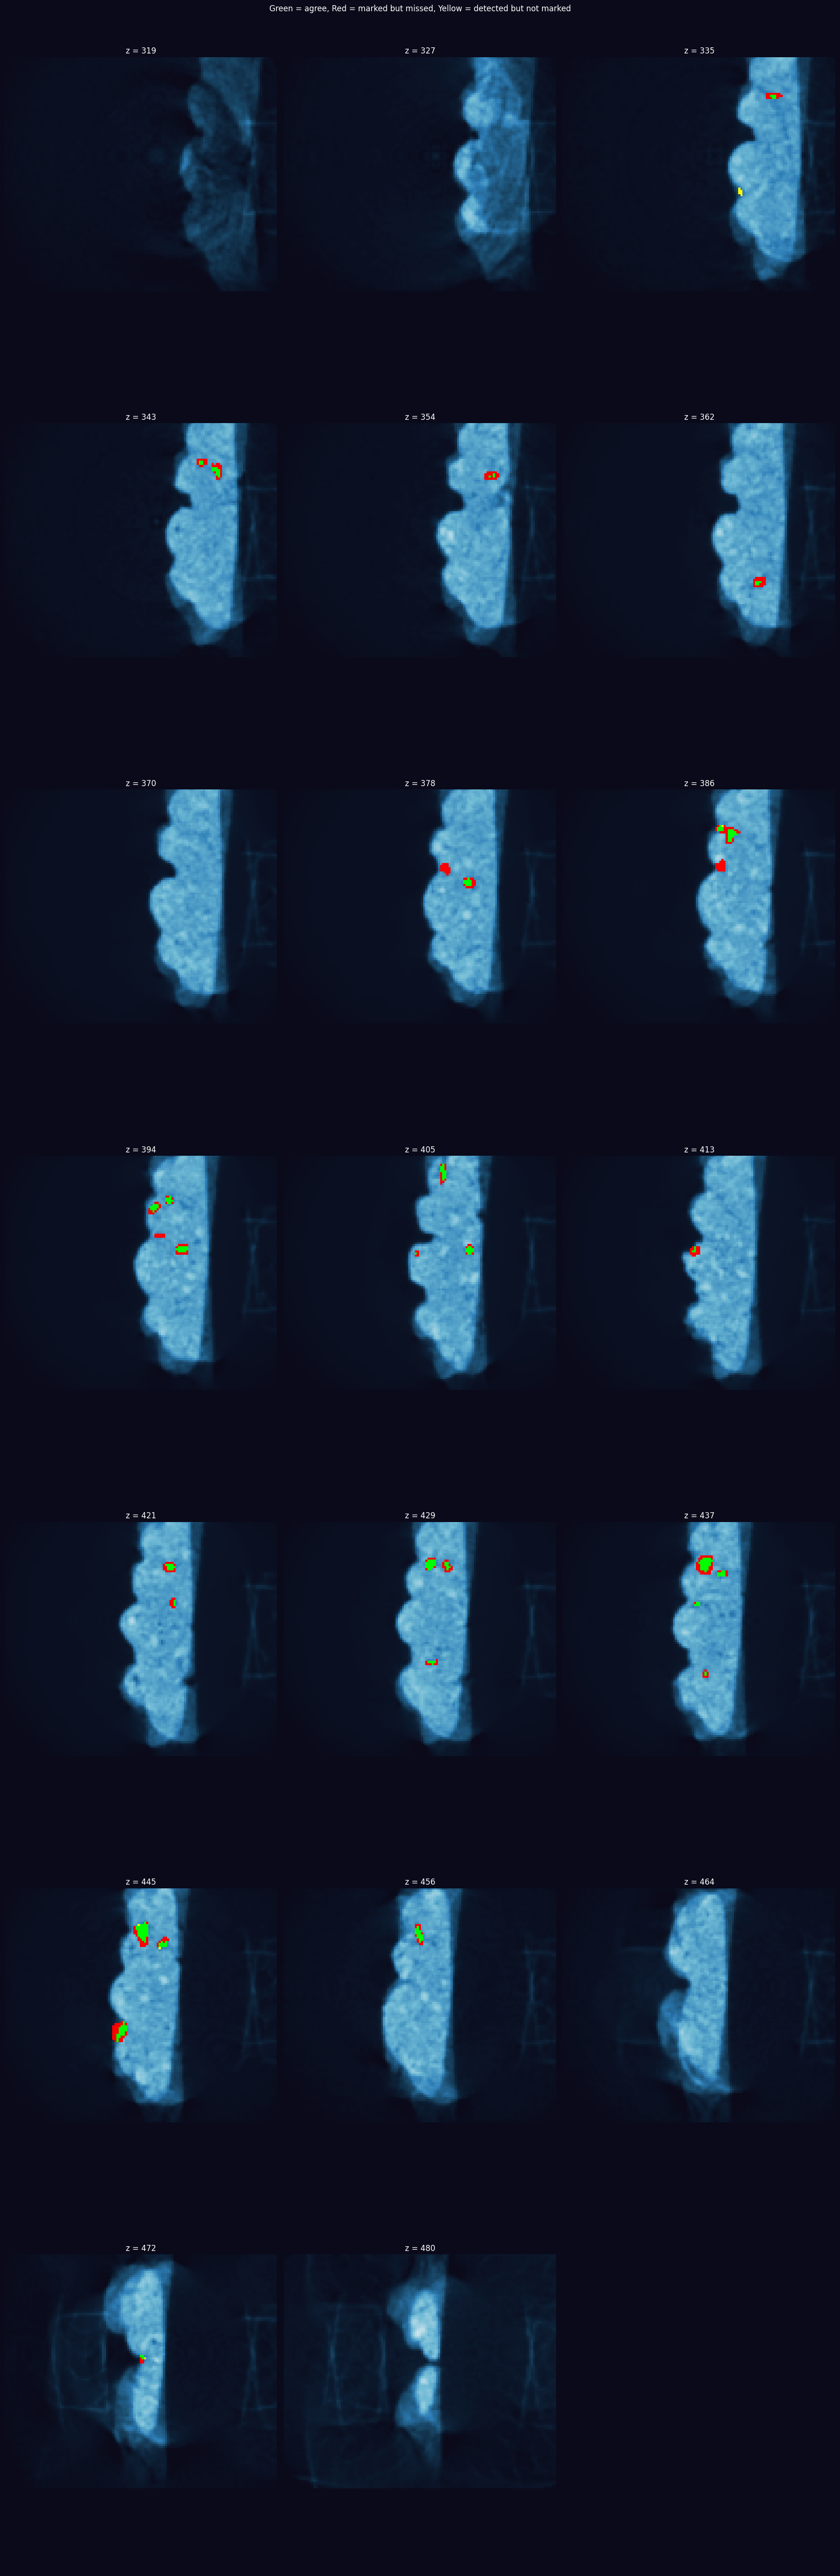

In [58]:
# validation: overlay (green agree, red missed, yellow extra)
cols = 3
rows_n = int(np.ceil(len(masks) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(6 * cols, 8 * rows_n), facecolor='#0a0a1a')
axes = np.array(axes).reshape(-1)
for ax in axes:
    ax.axis('off')

for ax, (z, (truth, pred)) in zip(axes, masks.items()):
    raw = Image.open(f"{test_folder}/raw/slice_{z}_raw.png").convert('RGB')
    picture = np.array(raw.resize((truth.shape[1], truth.shape[0]), Image.NEAREST))
    picture[truth & pred] = (0, 255, 0)
    picture[truth & ~pred] = (255, 0, 0)
    picture[~truth & pred] = (255, 255, 0)
    ax.imshow(picture)
    ax.set_title(f"z = {z}", color='white')

fig.suptitle("Green = agree, Red = marked but missed, Yellow = detected but not marked", color='white')
plt.tight_layout()
plt.savefig(f"{test_folder}/validation_overlay.png", dpi=200, facecolor='#0a0a1a')
plt.show()

## 9. Threshold sweep


In [59]:
inner_test = binary_erosion(test_envelope, ball(interior_margin))
z_marked = sorted(masks)
crop = (slice(ymin, ymax), slice(xmin, xmax))

truths = [masks[z][0] & inner_test[z][crop] for z in z_marked]      # marked bubbles
inners = [inner_test[z][crop] for z in z_marked]                     # scored area
slices_s = [test_vol_s[z][crop] for z in z_marked]                   # smoothed test slices
print(f"{len(z_marked)} marked slices, {sum(t.sum() for t in truths):,} marked bubble pixels")

20 marked slices, 730 marked bubble pixels


In [60]:
# the sweep: threshold = grey / 255, from grey 0 to 255
import pandas as pd

def ratio(a, b):
    return a / b if b else np.nan

vs_box = test_vol_s[test_box]
inner_box = inner_test[test_box]

rows = []
for g in range(0, 256):
    air_g = (vs_box < g / 255) & inner_box
    labels_g, n_regions = scipy_label(air_g)
    sizes_g = np.bincount(labels_g.ravel())[1:]
    bubbles_g = sizes_g[sizes_g >= min_bubble_voxels]

    # precision and recall on the marked slices (pixels)
    tp = fp = fn = tn = 0
    for s, t, inn in zip(slices_s, truths, inners):
        p = (s < g / 255) & inn                       # dark = predicted air
        tp += np.sum(p & t)
        fp += np.sum(p & ~t)
        fn += np.sum(~p & t)
        tn += np.sum(~p & ~t & inn)

    rows.append({"grey": g,
                 "bubbles": len(bubbles_g),
                 "bubble volume mm3": bubbles_g.sum() * voxel_mm3,
                 "precision": ratio(tp, tp + fp),
                 "recall": ratio(tp, tp + fn),
                 "FPR": ratio(fp, fp + tn)})          # false positive rate, used for the ROC curve

sweep = pd.DataFrame(rows)
sweep.to_csv("/content/threshold_sweep.csv", index=False)
display(sweep.iloc[::15].round(3))

,grey,bubbles,bubble volume mm3,precision,recall,FPR
0,0,0,0.000,NaN,0.000,0.000
15,15,0,0.000,NaN,0.000,0.000
30,30,0,0.000,NaN,0.000,0.000
45,45,0,0.000,NaN,0.000,0.000
60,60,0,0.000,NaN,0.000,0.000
75,75,0,0.000,NaN,0.000,0.000
90,90,0,0.000,NaN,0.000,0.000
105,105,0,0.000,NaN,0.000,0.000
120,120,0,0.000,NaN,0.000,0.000
135,135,1,1.600,0.429,0.004,0.000


In [61]:
# Precision and recall equal point
g_used = test_local_chosen * 255
found = sweep[(sweep["precision"] > 0) & (sweep["recall"] > 0) & (sweep["recall"] >= sweep["precision"])]

if len(found) > 0:
    equal = found.iloc[0]
    print(f"Precision and recall are about equal at grey {equal['grey']:.0f}: precision {equal['precision']:.2f}, recall {equal['recall']:.2f}")
else:
    equal = None
    print("Precision and recall never meet")
print(f"Threshold used by the algorithm: grey {g_used:.0f}")

Precision and recall are about equal at grey 152: precision 0.08, recall 0.10
Threshold used by the algorithm: grey 168


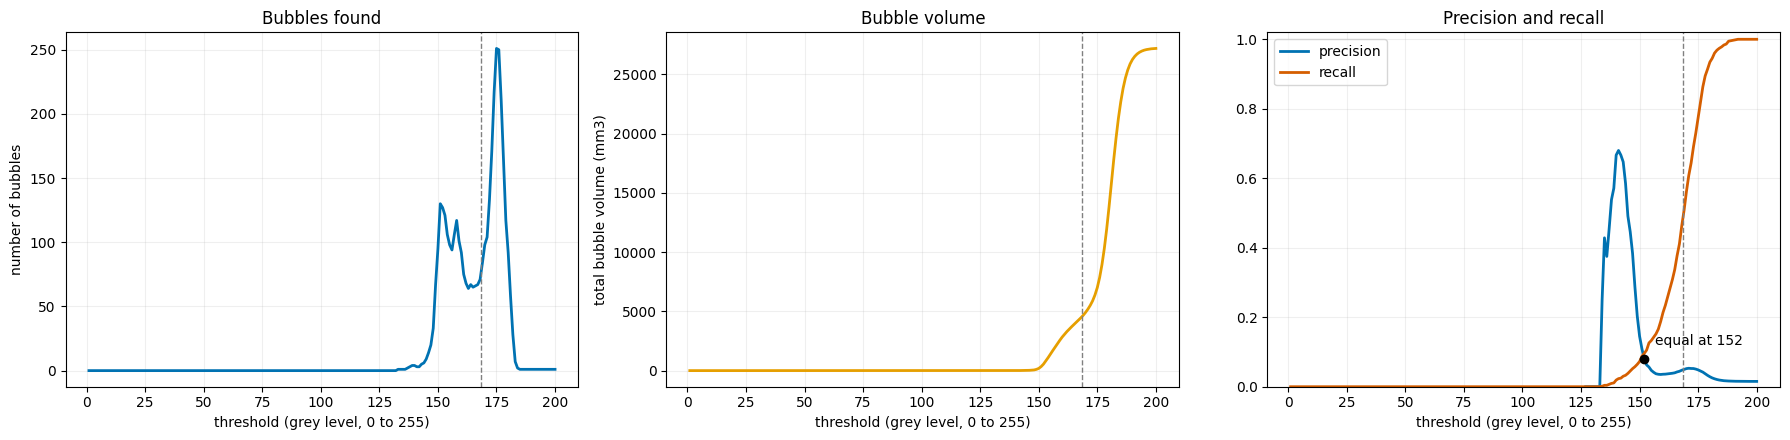

In [62]:
# plot: bubbles, bubble volume, precision and recall against the threshold
shown = sweep[(sweep["grey"] >= 1) & (sweep["grey"] <= 200)]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(shown["grey"], shown["bubbles"], color="#0072B2", lw=2)
ax[0].set_title("Bubbles found")
ax[0].set_ylabel("number of bubbles")

ax[1].plot(shown["grey"], shown["bubble volume mm3"], color="#E69F00", lw=2)
ax[1].set_title("Bubble volume")
ax[1].set_ylabel("total bubble volume (mm3)")

ax[2].plot(shown["grey"], shown["precision"], color="#0072B2", lw=2, label="precision")
ax[2].plot(shown["grey"], shown["recall"], color="#D55E00", lw=2, label="recall")
if equal is not None:
    ax[2].scatter([equal["grey"]], [equal["precision"]], color="black", zorder=3)
    ax[2].annotate(f"equal at {equal['grey']:.0f}", (equal["grey"], equal["precision"]), xytext=(8, 10), textcoords="offset points")
ax[2].set_title("Precision and recall")
ax[2].set_ylim(0, 1.02)
ax[2].legend()

for a in ax:
    a.axvline(g_used, color="gray", ls="--", lw=1)          # threshold used by the algorithm
    a.set_xlabel("threshold (grey level, 0 to 255)")
    a.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("/content/threshold_sweep.png", dpi=150)
plt.show()

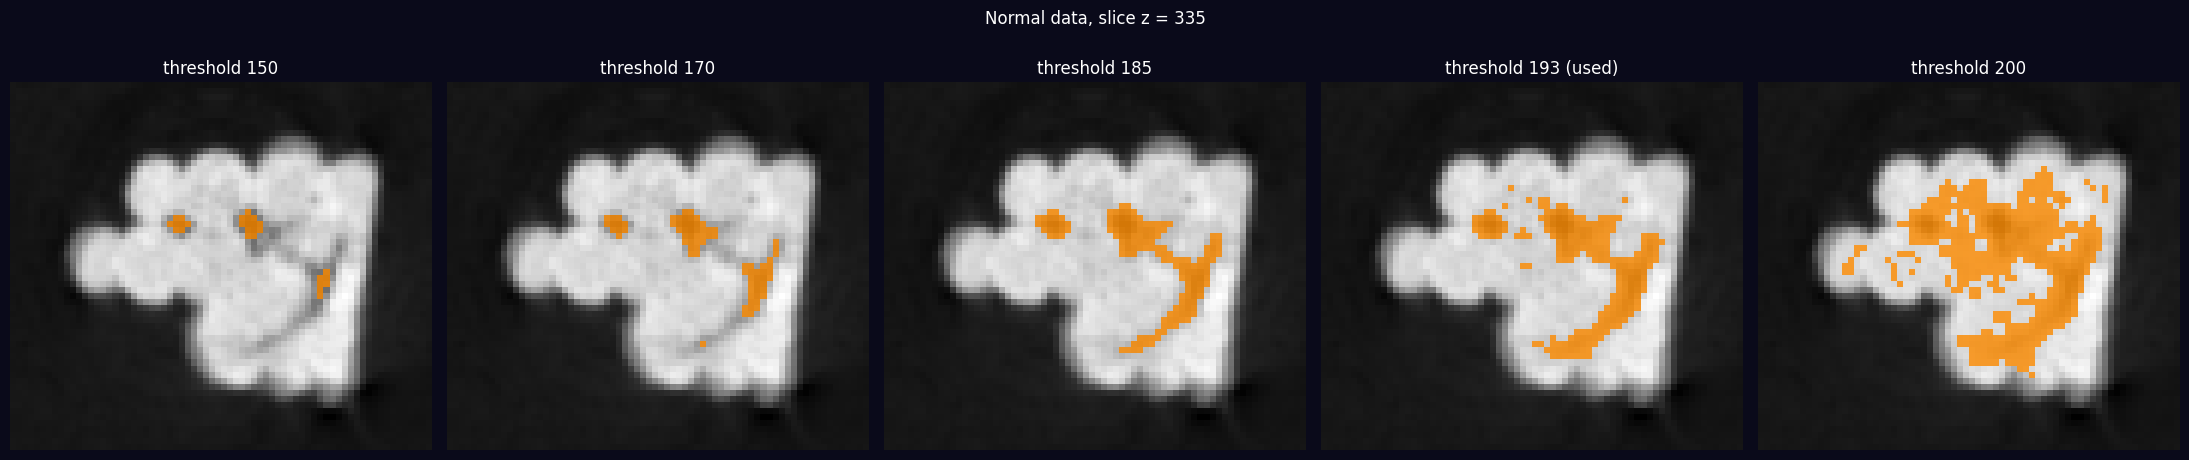

In [63]:
# same slice at different thresholds
g_normal = local_chosen * 255
thresholds_show = [150, 170, 185, int(round(g_normal)), 200]

air_n = (vol_s < local_chosen) & envelope_inner
z_n = int(np.argmax(air_n.sum(axis=(1, 2))))                 # slice with the most air at the used threshold

ys, xs = np.nonzero(envelope[z_n])
cut = (slice(max(ys.min() - 10, 0), ys.max() + 10), slice(max(xs.min() - 10, 0), xs.max() + 10))
img = vol_s[z_n][cut]

fig, axes = plt.subplots(1, 5, figsize=(22, 5), facecolor="#0a0a1a")
for ax, g in zip(axes, thresholds_show):
    overlay = np.zeros((*img.shape, 4))
    overlay[(img < g / 255) & envelope_inner[z_n][cut]] = [1, 0.55, 0, 0.8]
    ax.imshow(img, cmap="gray")
    ax.imshow(overlay)
    ax.set_title(f"threshold {g}" + (" (used)" if g == int(round(g_normal)) else ""), color="white")
    ax.axis("off")
plt.suptitle(f"Normal data, slice z = {z_n}", color="white")
plt.tight_layout()
plt.show()

### ROC curve and AUC

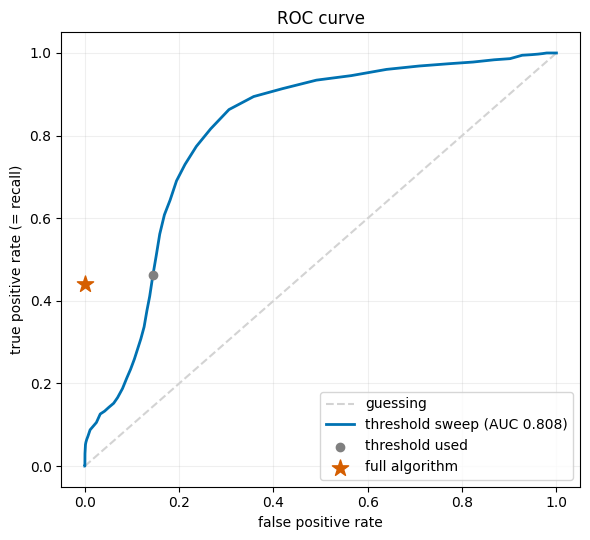

AUC of the threshold sweep: 0.808   (1 = perfect, 0.5 = guessing)
Best threshold by Youden index: grey 177, true positive rate 0.863, false positive rate 0.306
Threshold used: grey 168, true positive rate 0.463, false positive rate 0.144
Full algorithm: true positive rate 0.440, false positive rate 0.0002


In [64]:
# ROC curve: recall (true positive rate) against false positive rate, one point per threshold
order = np.lexsort((sweep["recall"].values, sweep["FPR"].values))
fpr = sweep["FPR"].values[order]
tpr = sweep["recall"].values[order]

trapezoid = getattr(np, "trapezoid", None) or np.trapz          # area under the curve
auc = trapezoid(tpr, fpr)

best = int((sweep["recall"] - sweep["FPR"]).idxmax())            # Youden index: furthest above the diagonal
used = sweep.iloc[int(round(g_used))]

# the full algorithm
tp = fp = fn = tn = 0
for z, t, inn in zip(z_marked, truths, inners):
    p = test_bubbles[z][crop] & inn
    tp += np.sum(p & t)
    fp += np.sum(p & ~t)
    fn += np.sum(~p & t)
    tn += np.sum(~p & ~t & inn)
algo_fpr, algo_tpr = ratio(fp, fp + tn), ratio(tp, tp + fn)

plt.figure(figsize=(6, 5.5))
plt.plot([0, 1], [0, 1], color="lightgray", ls="--", label="guessing")
plt.plot(fpr, tpr, color="#0072B2", lw=2, label=f"threshold sweep (AUC {auc:.3f})")
plt.scatter([used["FPR"]], [used["recall"]], color="gray", zorder=3, label="threshold used")
plt.scatter([algo_fpr], [algo_tpr], color="#D55E00", marker="*", s=150, zorder=3, label="full algorithm")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate (= recall)")
plt.title("ROC curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("/content/threshold_roc.png", dpi=150)
plt.show()

print(f"AUC of the threshold sweep: {auc:.3f}   (1 = perfect, 0.5 = guessing)")
print(f"Best threshold by Youden index: grey {best}, true positive rate {sweep['recall'][best]:.3f}, false positive rate {sweep['FPR'][best]:.3f}")
print(f"Threshold used: grey {g_used:.0f}, true positive rate {used['recall']:.3f}, false positive rate {used['FPR']:.3f}")
print(f"Full algorithm: true positive rate {algo_tpr:.3f}, false positive rate {algo_fpr:.4f}")